In [1]:

# 1. Установка и импорт библиотек

!pip -q install datasets pandas numpy matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from itertools import islice

print("Библиотеки успешно установлены!")

Библиотеки успешно установлены!


In [2]:

# 2. Подключение к статическому датасету Hugging Face

DATASET_NAME = "Otter21/ARGO_Profiles"

dataset = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True
)

print("Подключение успешно!")
print("Источник:", DATASET_NAME)

README.md:   0%|          | 0.00/7.61k [00:00<?, ?B/s]

Подключение успешно!
Источник: Otter21/ARGO_Profiles


In [3]:

# 3. Получение первых 100 профилей

records = list(islice(dataset, 100))

df = pd.DataFrame(records)

print("Размер выборки:", df.shape)

print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nПервые 5 записей:")
display(df.head())

Размер выборки: (100, 16)

Названия столбцов:
['_id', 'basin', 'timestamp', 'date_updated_argovis', 'source', 'cycle_number', 'geolocation_argoqc', 'profile_direction', 'timestamp_argoqc', 'vertical_sampling_scheme', 'data', 'data_info', 'metadata', 'geolocation.type', 'geolocation.coordinates', 'data_warning']

Первые 5 записей:


,_id,basin,timestamp,date_updated_argovis,source,cycle_number,geolocation_argoqc,profile_direction,timestamp_argoqc,vertical_sampling_scheme,data,data_info,metadata,geolocation.type,geolocation.coordinates,data_warning
0,4903545_108,1,2024-11-27T23:59:58.002Z,2025-02-22T06:49:59.970Z,"[{'source': ['argo_core'], 'url': 'ftp://ftp.i...",108,1,A,1,Primary sampling: averaged [nominal 2 dbar bin...,"[[0.48, 1.04, 2, 3, 4.04, 5.04, 6.04, 7.04, 8....","[['pressure', 'pressure_argoqc', 'salinity', '...",['4903545_m0'],Point,"[-87.21012, 26.38176]",None
1,5905880_053,2,2024-11-27T23:57:56.000Z,2024-11-28T09:06:08.440Z,"[{'source': ['argo_core'], 'url': 'ftp://ftp.i...",53,1,A,1,Primary sampling: averaged [bin average for 1 ...,"[[4.57, 6.27, 8.27, 10.27, 12.27, 14.370001, 1...","[['pressure', 'pressure_argoqc', 'salinity', '...",['5905880_m0'],Point,"[150.458, 22.136]",None
2,4903409_150,2,2024-11-27T23:53:53.664Z,2025-10-01T07:26:30.160Z,"[{'source': ['argo_core'], 'url': 'ftp://ftp.i...",150,1,A,1,Primary sampling: averaged [nominal 2 dbar b...,"[[0.96, 2, 3.04, 4.08, 5.04, 6, 6.96, 7.96, 9,...","[['pressure', 'pressure_argoqc', 'salinity', '...",['4903409_m1'],Point,"[-150.33362, 32.33186]",None
3,7902121_005,2,2024-11-27T23:52:36.002Z,2025-11-24T06:53:19.802Z,"[{'source': ['argo_bgc'], 'url': 'ftp://ftp.if...",5,1,A,1,Primary sampling: mixed [deeper than nominal 9...,"[[None, None, 0.000357, None, None, 0.000368, ...","[['bbp700', 'bbp700_argoqc', 'chla', 'chla_arg...",['7902121_m1'],Point,"[-133.4683, -27.6106]",None
4,1902066_295,1,2024-11-27T23:50:16.002Z,2024-12-08T06:36:06.877Z,"[{'source': ['argo_core'], 'url': 'ftp://ftp.i...",295,1,A,1,Primary sampling: averaged [nominal 2 dbar bin...,"[[1.04, 2, 2.96, 3.96, 5, 6, 6.96, 7.96, 8.96,...","[['pressure', 'pressure_argoqc', 'salinity', '...",['1902066_m0'],Point,"[-11.56395, -33.15373]",None


In [4]:

# 4. Первичный анализ данных

print("Информация о таблице:")
df.info()

print("\nКоличество пропусков:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nКоличество уникальных профилей:")
print(df["_id"].nunique())

print("\nВременной диапазон:")
print("От:", df["timestamp"].min())
print("До:", df["timestamp"].max())

print("\nКоличество океанических бассейнов:")
print(df["basin"].nunique())

Информация о таблице:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   _id                       100 non-null    object
 1   basin                     100 non-null    int64 
 2   timestamp                 100 non-null    object
 3   date_updated_argovis      100 non-null    object
 4   source                    100 non-null    object
 5   cycle_number              100 non-null    int64 
 6   geolocation_argoqc        100 non-null    int64 
 7   profile_direction         100 non-null    object
 8   timestamp_argoqc          100 non-null    int64 
 9   vertical_sampling_scheme  100 non-null    object
 10  data                      100 non-null    object
 11  data_info                 100 non-null    object
 12  metadata                  100 non-null    object
 13  geolocation.type          100 non-null    object
 14  geolo

,0
data_warning,98
_id,0
timestamp,0
basin,0
source,0
cycle_number,0
geolocation_argoqc,0
date_updated_argovis,0
profile_direction,0
timestamp_argoqc,0



Количество уникальных профилей:
100

Временной диапазон:
От: 2024-11-27T18:47:59.999Z
До: 2024-11-27T23:59:58.002Z

Количество океанических бассейнов:
8


In [8]:

import json
import ast

# Проверяем несколько профилей
for i in [0, 1, 3]:
    p = records[i]

    print("\n" + "=" * 60)
    print("Профиль:", p["_id"])

    for field in ["data", "data_info",
                  "geolocation.coordinates", "source"]:

        value = p.get(field)

        print(f"\nПоле: {field}")
        print("Тип:", type(value))
        print("Пример:", repr(value)[:500])

        if isinstance(value, (list, tuple)):
            print("Количество элементов:", len(value))


Профиль: 4903545_108

Поле: data
Тип: <class 'str'>
Пример: '[[0.48, 1.04, 2, 3, 4.04, 5.04, 6.04, 7.04, 8.04, 9.04, 10.28, 12.04, 13.96, 15.96, 18, 19.959999, 21.959999, 24.040001, 25.959999, 27.959999, 29.959999, 31.959999, 34, 35.959999, 37.959999, 40, 42.040001, 44.080002, 46.040001, 48, 50, 52.040001, 54.040001, 56, 58.040001, 60.040001, 62.040001, 64, 65.959999, 67.959999, 70, 72, 74.040001, 76.040001, 78, 80, 82.040001, 84, 85.959999, 87.959999, 90, 92, 94, 96.040001, 98.040001, 100.040001, 102.080002, 104.040001, 106, 108, 109.959999, 112, 114.04

Поле: data_info
Тип: <class 'str'>
Пример: "[['pressure', 'pressure_argoqc', 'salinity', 'salinity_argoqc', 'temperature', 'temperature_argoqc'], ['units', 'data_keys_mode'], [['decibar', 'R'], [None, None], ['psu', 'R'], [None, None], ['degree_Celsius', 'R'], [None, None]]]"

Поле: geolocation.coordinates
Тип: <class 'str'>
Пример: '[-87.21012, 26.38176]'

Поле: source
Тип: <class 'str'>
Пример: "[{'source': ['argo_core'], 'url': 'f

In [9]:

def parse_value(value):
    """Преобразование сериализованных структур в Python-объекты."""

    if not isinstance(value, str):
        return value

    value = value.strip()

    if not value:
        return None

    for parser in (json.loads, ast.literal_eval):
        try:
            return parser(value)
        except (ValueError, SyntaxError, TypeError):
            continue

    return value


# Преобразуем вложенные поля
for record in records:
    for field in ["data", "data_info",
                  "geolocation.coordinates", "source"]:

        if field in record:
            record[field] = parse_value(record[field])


# Создаём обновлённую таблицу
df = pd.DataFrame(records)

print("Преобразование завершено")

for field in ["data", "data_info",
              "geolocation.coordinates", "source"]:
    print(field, ":", type(records[0].get(field)))


Преобразование завершено
data : <class 'list'>
data_info : <class 'list'>
geolocation.coordinates : <class 'list'>
source : <class 'list'>


Количество корректных координат: 100


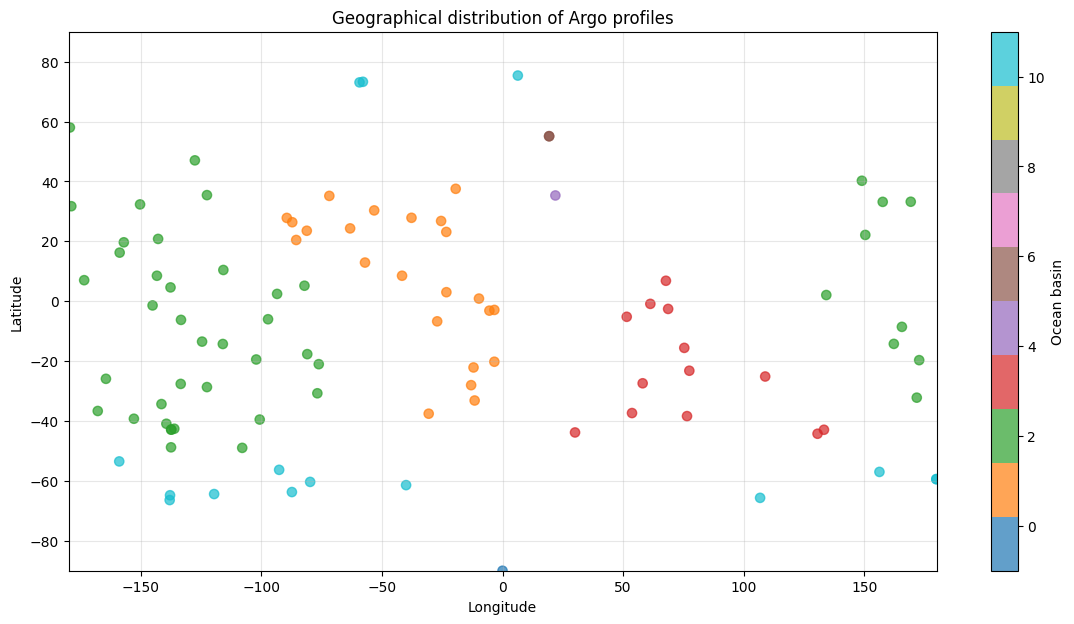

In [10]:

# Извлечение координат
df["longitude"] = df["geolocation.coordinates"].apply(
    lambda x: float(x[0])
    if isinstance(x, (list, tuple)) and len(x) >= 2
    else np.nan
)

df["latitude"] = df["geolocation.coordinates"].apply(
    lambda x: float(x[1])
    if isinstance(x, (list, tuple)) and len(x) >= 2
    else np.nan
)

print("Количество корректных координат:",
      df[["longitude", "latitude"]].dropna().shape[0])

plt.figure(figsize=(14, 7))

plt.scatter(
    df["longitude"],
    df["latitude"],
    c=df["basin"],
    cmap="tab10",
    s=45,
    alpha=0.7
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical distribution of Argo profiles")
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(alpha=0.3)
plt.colorbar(label="Ocean basin")
plt.show()

In [11]:

for i in [0, 1, 3]:
    p = records[i]

    print("\nПРОФИЛЬ:", p["_id"])
    print("Тип data:", type(p["data"]))

    if isinstance(p["data"], list):
        print("Количество массивов:", len(p["data"]))

        for j, values in enumerate(p["data"][:5]):
            print(
                f"Массив {j}:",
                "количество значений =", len(values)
                if isinstance(values, list) else "не список",
                "пример =", repr(values)[:150]
            )

    print("DATA_INFO:")
    print(repr(p["data_info"])[:1000])



ПРОФИЛЬ: 4903545_108
Тип data: <class 'list'>
Количество массивов: 6
Массив 0: количество значений = 1013 пример = [0.48, 1.04, 2, 3, 4.04, 5.04, 6.04, 7.04, 8.04, 9.04, 10.28, 12.04, 13.96, 15.96, 18, 19.959999, 21.959999, 24.040001, 25.959999, 27.959999, 29.95999
Массив 1: количество значений = 1013 пример = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
Массив 2: количество значений = 1013 пример = [36.380001, 36.380001, 36.380001, 36.381001, 36.381001, 36.380001, 36.380001, 36.381001, 36.380001, 36.381001, 36.381001, 36.380001, 36.380001, 36.381
Массив 3: количество значений = 1013 пример = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
Массив 4: количество значений = 1013 пример = [27.268999, 27.271, 27.275, 27.271999, 27.271, 27.273001, 27.275999, 27.274, 27.274, 27.273001, 

In [12]:
# ЭТАП 2. НОРМАЛИЗАЦИЯ ПРОФИЛЕЙ ARGO
# Формирование таблицы измерений для слоя Processed

import pandas as pd
import numpy as np

normalized_profiles = []
normalization_errors = []

def normalize_profile(profile):

    profile_id = profile.get("_id")

    # Получаем структуру данных
    data = profile.get("data")
    data_info = profile.get("data_info")

    if not isinstance(data, list) or not isinstance(data_info, list):
        raise ValueError("Некорректная структура data/data_info")

    if len(data_info) < 3:
        raise ValueError("Отсутствует описание параметров data_info")

    parameter_names = data_info[0]
    parameter_metadata = data_info[2]

    if len(parameter_names) != len(data):
        raise ValueError(
            f"Количество параметров ({len(parameter_names)}) "
            f"не совпадает с количеством массивов ({len(data)})"
        )

    # Проверяем длину массивов
    lengths = [len(arr) for arr in data]

    if len(set(lengths)) != 1:
        raise ValueError("Массивы имеют разную длину")

    # Связываем названия параметров с измерениями
    measurements = {
        name: values
        for name, values in zip(parameter_names, data)
    }

    # Формируем таблицу одного профиля
    profile_df = pd.DataFrame(measurements)

    # Извлекаем координаты
    coordinates = profile.get("geolocation.coordinates")

    longitude = (
        coordinates[0]
        if isinstance(coordinates, list) and len(coordinates) >= 2
        else np.nan
    )

    latitude = (
        coordinates[1]
        if isinstance(coordinates, list) and len(coordinates) >= 2
        else np.nan
    )

    # Информация об источнике
    sources = profile.get("source", [])

    source_types = []
    source_urls = []

    if isinstance(sources, list):
        for source in sources:
            if isinstance(source, dict):
                source_types.extend(source.get("source", []))

                if source.get("url"):
                    source_urls.append(source["url"])

    # Информация о профиле
    profile_df["profile_id"] = profile_id
    profile_df["basin"] = profile.get("basin")
    profile_df["timestamp"] = profile.get("timestamp")
    profile_df["cycle_number"] = profile.get("cycle_number")
    profile_df["profile_direction"] = profile.get("profile_direction")
    profile_df["longitude"] = longitude
    profile_df["latitude"] = latitude
    profile_df["source_type"] = ",".join(source_types)
    profile_df["source_url"] = ";".join(source_urls)

    return profile_df


# Обрабатываем все загруженные профили
for profile in records:

    try:
        result = normalize_profile(profile)
        normalized_profiles.append(result)

    except Exception as error:
        normalization_errors.append({
            "profile_id": profile.get("_id"),
            "error": str(error)
        })


# Объединяем все профили
if normalized_profiles:
    df_processed = pd.concat(
        normalized_profiles,
        ignore_index=True
    )
else:
    df_processed = pd.DataFrame()


print("НОРМАЛИЗАЦИЯ ЗАВЕРШЕНА")
print("Количество исходных профилей:", len(records))
print("Успешно обработано:", len(normalized_profiles))
print("Ошибок:", len(normalization_errors))
print("Размер Processed:", df_processed.shape)

print("\nПервые 10 строк:")
display(df_processed.head(10))


НОРМАЛИЗАЦИЯ ЗАВЕРШЕНА
Количество исходных профилей: 100
Успешно обработано: 100
Ошибок: 0
Размер Processed: (80948, 45)

Первые 10 строк:


/tmp/ipykernel_570/2840644533.py:109: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_processed = pd.concat(


,pressure,pressure_argoqc,salinity,salinity_argoqc,temperature,temperature_argoqc,profile_id,basin,timestamp,cycle_number,...,cdom,cdom_argoqc,down_irradiance380,down_irradiance380_argoqc,down_irradiance412,down_irradiance412_argoqc,down_irradiance490,down_irradiance490_argoqc,downwelling_par,downwelling_par_argoqc
0,0.48,1,36.380001,1.0,27.268999,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.04,1,36.380001,1.0,27.271000,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.00,1,36.380001,1.0,27.275000,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3.00,1,36.381001,1.0,27.271999,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4.04,1,36.381001,1.0,27.271000,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,5.04,1,36.380001,1.0,27.273001,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,6.04,1,36.380001,1.0,27.275999,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,7.04,1,36.381001,1.0,27.274000,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,8.04,1,36.380001,1.0,27.274000,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,9.04,1,36.381001,1.0,27.273001,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
# КОНТРОЛЬ КАЧЕСТВА PROCESSED

print("1. Столбцы таблицы:")
print(df_processed.columns.tolist())

print("\n2. Количество измерений:")
print(len(df_processed))

print("\n3. Количество профилей:")
print(df_processed["profile_id"].nunique())

print("\n4. Количество бассейнов:")
print(df_processed["basin"].nunique())

print("\n5. Источники:")
print(df_processed["source_type"].value_counts())

print("\n6. Наличие основных параметров:")

for parameter in [
    "pressure",
    "temperature",
    "salinity",
    "doxy",
    "nitrate",
    "chla",
    "bbp700",
    "ph_in_situ_total"
]:
    if parameter in df_processed.columns:
        print(
            parameter,
            "-",
            "измерений:",
            df_processed[parameter].notna().sum()
        )
    else:
        print(parameter, "- отсутствует")

print("\n7. Ошибки обработки:")
display(pd.DataFrame(normalization_errors))

1. Столбцы таблицы:
['pressure', 'pressure_argoqc', 'salinity', 'salinity_argoqc', 'temperature', 'temperature_argoqc', 'profile_id', 'basin', 'timestamp', 'cycle_number', 'profile_direction', 'longitude', 'latitude', 'source_type', 'source_url', 'bbp700', 'bbp700_argoqc', 'chla', 'chla_argoqc', 'chla_fluorescence', 'chla_fluorescence_argoqc', 'doxy', 'doxy_argoqc', 'nitrate', 'nitrate_argoqc', 'ph_in_situ_total', 'ph_in_situ_total_argoqc', 'salinity_sfile', 'salinity_sfile_argoqc', 'temperature_sfile', 'temperature_sfile_argoqc', 'bbp532', 'bbp532_argoqc', 'cp660', 'cp660_argoqc', 'cdom', 'cdom_argoqc', 'down_irradiance380', 'down_irradiance380_argoqc', 'down_irradiance412', 'down_irradiance412_argoqc', 'down_irradiance490', 'down_irradiance490_argoqc', 'downwelling_par', 'downwelling_par_argoqc']

2. Количество измерений:
80948

3. Количество профилей:
100

4. Количество бассейнов:
8

5. Источники:
source_type
argo_core                                 58098
argo_bgc,argo_core        

""


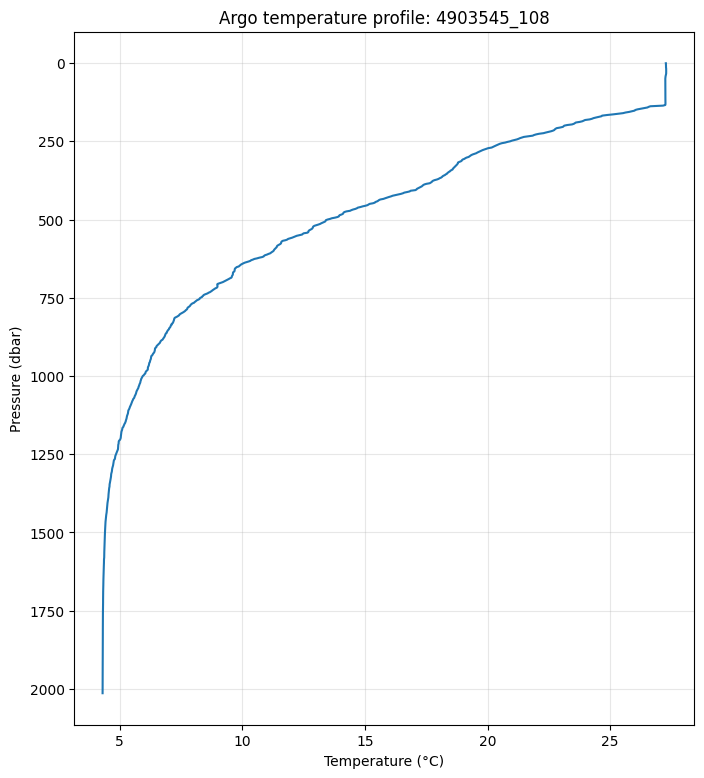

In [14]:
# ТЕМПЕРАТУРНЫЙ ПРОФИЛЬ

# Берём первый профиль, содержащий температуру
profile_ids = df_processed.loc[
    df_processed["temperature"].notna(),
    "profile_id"
].unique()

if len(profile_ids) > 0:

    selected_id = profile_ids[0]

    sample = df_processed[
        df_processed["profile_id"] == selected_id
    ].copy()

    sample = sample.dropna(
        subset=["pressure", "temperature"]
    )

    sample = sample.sort_values("pressure")

    plt.figure(figsize=(8, 9))

    plt.plot(
        sample["temperature"],
        sample["pressure"]
    )

    plt.gca().invert_yaxis()

    plt.xlabel("Temperature (°C)")
    plt.ylabel("Pressure (dbar)")
    plt.title(f"Argo temperature profile: {selected_id}")

    plt.grid(alpha=0.3)
    plt.show()

else:
    print("Температурные измерения не найдены")

In [15]:

# Сохранение тестового Processed

df_processed.to_csv(
    "argo_processed_sample.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Файл сохранён: argo_processed_sample.csv")

from google.colab import files
files.download("argo_processed_sample.csv")

Файл сохранён: argo_processed_sample.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# ЭТАП 3. ПОДКЛЮЧЕНИЕ К ARGOVIS API

!pip -q install requests pandas

import requests
import json
import pandas as pd
from datetime import datetime, timezone

API_BASE = "https://argovis-api.colorado.edu"

print("Argovis API:", API_BASE)
print("Время проверки:", datetime.now(timezone.utc))


Argovis API: https://argovis-api.colorado.edu
Время проверки: 2026-11-24 15:18:04.220540+00:00


In [17]:
# ПРОВЕРКА ДОСТУПНОСТИ API

response = requests.get(
    f"{API_BASE}/ping",
    timeout=30
)

print("HTTP статус:", response.status_code)
print("Ответ сервера:", response.text[:1000])

response.raise_for_status()

print("\nAPI доступен!")

HTTP статус: 200
Ответ сервера: OK

API доступен!


In [18]:
# ПОЛУЧЕНИЕ ОБЩЕЙ ИНФОРМАЦИИ ОБ ARGO

response = requests.get(
    f"{API_BASE}/argo/overview",
    timeout=60
)

print("HTTP статус:", response.status_code)

response.raise_for_status()

argo_overview = response.json()

print("\nИнформация об Argo:")
print(json.dumps(
    argo_overview,
    indent=2,
    ensure_ascii=False
)[:5000])

HTTP статус: 200

Информация об Argo:
[
  {
    "_id": "argo_overview",
    "summary": {
      "nCore": 3442089,
      "nBGC": 415351,
      "nDeep": 66443,
      "mostrecent": "2026-12-27T14:48:20.000Z",
      "latest_argovis_update": "2026-11-24T09:13:44.646Z",
      "datacenters": [
        "AO",
        "JA",
        "IN",
        "HZ",
        "NM",
        "CS",
        "BO",
        "KO",
        "KM",
        "ME",
        "IF"
      ]
    }
  }
]


In [19]:
# ПОЛУЧЕНИЕ ПРОФИЛЯ ПО ИДЕНТИФИКАТОРУ

profile_id = "4903545_108"

response = requests.get(
    f"{API_BASE}/argo",
    params={"id": profile_id},
    timeout=60
)

print("HTTP статус:", response.status_code)
print("URL запроса:", response.url)

if response.status_code == 200:
    api_data = response.json()

    print("\nПолучение успешно!")

    print(json.dumps(
        api_data if isinstance(api_data, dict)
        else api_data[:1],
        indent=2,
        ensure_ascii=False
    )[:4000])

else:
    print("Ответ API:")
    print(response.text[:2000])


HTTP статус: 200
URL запроса: https://argovis-api.colorado.edu/argo?id=4903545_108

Получение успешно!
[
  {
    "_id": "4903545_108",
    "geolocation": {
      "type": "Point",
      "coordinates": [
        -87.21012,
        26.38176
      ]
    },
    "basin": 1,
    "timestamp": "2024-11-27T23:59:58.002Z",
    "date_updated_argovis": "2026-11-04T09:18:30.006Z",
    "source": [
      {
        "source": [
          "argo_core"
        ],
        "url": "ftp://ftp.ifremer.fr/ifremer/argo/dac/aoml/4903545/profiles/D4903545_108.nc",
        "date_updated": "2026-11-03T12:46:44.000Z"
      }
    ],
    "cycle_number": 108,
    "geolocation_argoqc": 1,
    "profile_direction": "A",
    "timestamp_argoqc": 1,
    "vertical_sampling_scheme": "Primary sampling: averaged [nominal 2 dbar binned data sampled at 0.5 Hz from a SBE41CP]",
    "data_info": [
      [
        "pressure",
        "pressure_argoqc",
        "salinity",
        "salinity_argoqc",
        "temperature",
        "tempe

In [20]:
# СОХРАНЕНИЕ RAW-ДАННЫХ

!pip -q install datasets

from datasets import load_dataset
import json
import os

RAW_DIR = "data/raw/static"
os.makedirs(RAW_DIR, exist_ok=True)

raw_dataset = load_dataset(
    "Otter21/ARGO_Profiles",
    split="train",
    streaming=True
)

raw_records = []

for record in raw_dataset:
    raw_records.append(record)

    if len(raw_records) >= 100:
        break

raw_path = os.path.join(
    RAW_DIR,
    "argo_profiles_sample.jsonl"
)

with open(raw_path, "w", encoding="utf-8") as file:
    for record in raw_records:
        file.write(
            json.dumps(record, ensure_ascii=False) + "\n"
        )

print("RAW-файл сохранён:", raw_path)
print("Количество профилей:", len(raw_records))
print("Размер файла:", os.path.getsize(raw_path), "байт")


RAW-файл сохранён: data/raw/static/argo_profiles_sample.jsonl
Количество профилей: 100
Размер файла: 4457668 байт


ЭТАП 8. ОПЕРАТИВНАЯ ЗАГРУЗКА ДАННЫХ ИЗ ARGOVIS API

In [22]:
# 8.1. ПОЛУЧЕНИЕ СПИСКА ПРОФИЛЕЙ ИЗ ARGOVIS API

from datetime import datetime, timedelta, timezone
import requests
import json

end_date = datetime.now(timezone.utc)
start_date = end_date - timedelta(days=30)

params = {
    "startDate": start_date.strftime("%Y-%m-%dT%H:%M:%S.000Z"),
    "endDate": end_date.strftime("%Y-%m-%dT%H:%M:%S.000Z")
}

headers = {
    "x-argokey": "guest"
}

print("Период загрузки:")
print("Начало:", params["startDate"])
print("Конец:", params["endDate"])

response = requests.get(
    f"{API_BASE}/argo",
    params=params,
    headers=headers,
    timeout=120
)

print("\nHTTP статус:", response.status_code)
print("Ответ сервера:", response.text[:2000])

if response.status_code == 200:

    api_metadata = response.json()

    if not isinstance(api_metadata, list):
        raise ValueError("Неожиданный формат ответа API")

    print("\nУспешно получены данные!")
    print("Количество профилей:", len(api_metadata))

    if api_metadata:
        print("\nПервый профиль:")
        print(json.dumps(
            api_metadata[0],
            ensure_ascii=False,
            indent=2
        )[:2000])

else:
    api_metadata = []
    print("\nЗагрузка не выполнена. Нужно проверить ответ API.")



Период загрузки:
Начало: 2026-10-25T15:24:39.000Z
Конец: 2026-11-24T15:24:39.000Z

HTTP статус: 200
Ответ сервера: [
{"_id":"7900990_178","geolocation":{"type":"Point","coordinates":[-49.38049,-61.58905]},"basin":10,"timestamp":"2026-11-24T04:59:55.000Z","date_updated_argovis":"2026-11-24T07:40:53.422Z","source":[{"source":["argo_core"],"url":"ftp://ftp.ifremer.fr/ifremer/argo/dac/coriolis/7900990/profiles/R7900990_178.nc","date_updated":"2026-11-24T05:51:45.000Z"}],"cycle_number":178,"geolocation_argoqc":1,"profile_direction":"A","timestamp_argoqc":1,"vertical_sampling_scheme":"Primary sampling: discrete [1 sample,50dbar interval from 2000 to 800dbar;1 sample,25dbar interval from 800 to 700dbar;1 sample,10dbar interval from 700 to 200dbar;1 sample,4dbar interval from 200 to 40dbar;1 sample,2dbar interval from 40 to 4dbar]","data_info":[["pressure","pressure_argoqc","salinity","salinity_argoqc","temperature","temperature_argoqc"],["units","data_keys_mode"],[["decibar","A"],[null,null],

In [23]:
# 8.2. ЗАГРУЗКА ПОЛНЫХ ПРОФИЛЕЙ С ИЗМЕРЕНИЯМИ

MAX_PROFILES = 20

headers = {
    "x-argokey": "guest"
}

selected_profiles = api_metadata[:MAX_PROFILES]

api_profiles = []
api_errors = []

data_parameters = "pressure,salinity,temperature"

for i, profile in enumerate(selected_profiles, 1):

    profile_id = profile["_id"]

    try:
        response = requests.get(
            f"{API_BASE}/argo",
            params={
                "id": profile_id,
                "data": data_parameters
            },
            headers=headers,
            timeout=60
        )

        response.raise_for_status()

        result = response.json()

        if isinstance(result, list):
            api_profiles.extend(result)
        elif isinstance(result, dict):
            api_profiles.append(result)

        print(f"{i}/{MAX_PROFILES}: {profile_id} — OK")

    except Exception as e:
        api_errors.append({
            "profile_id": profile_id,
            "error": str(e)
        })
        print(f"{i}/{MAX_PROFILES}: {profile_id} — ERROR: {e}")

    time.sleep(0.5)

print("\nРЕЗУЛЬТАТ")
print("Загружено профилей:", len(api_profiles))
print("Ошибок:", len(api_errors))

if api_profiles:
    print("\nПоля первого профиля:")
    print(list(api_profiles[0].keys()))

    print("\nНаличие измерений:",
          "data" in api_profiles[0])

    if "data" in api_profiles[0]:
        print("Тип data:", type(api_profiles[0]["data"]))


1/20: 7900990_178 — OK
2/20: 6903051_245 — OK
3/20: 7900534_273 — OK
4/20: 4903552_267 — OK
5/20: 4903821_054 — OK
6/20: 1902395_181 — OK
7/20: 5905625_036 — OK
8/20: 4903817_156 — OK
9/20: 4903790_095 — OK
10/20: 6999985_058 — OK
11/20: 1902263_234 — OK
12/20: 4903014_286 — OK
13/20: 5907282_167 — OK
14/20: 6990641_036 — OK
15/20: 4903553_261 — OK
16/20: 5906177_244 — OK
17/20: 5906688_073 — OK
18/20: 3902266_069 — OK
19/20: 4903901_026 — OK
20/20: 5905719_304 — OK

РЕЗУЛЬТАТ
Загружено профилей: 20
Ошибок: 0

Поля первого профиля:
['_id', 'geolocation', 'basin', 'timestamp', 'date_updated_argovis', 'source', 'cycle_number', 'geolocation_argoqc', 'profile_direction', 'timestamp_argoqc', 'vertical_sampling_scheme', 'data', 'data_info', 'metadata']

Наличие измерений: True
Тип data: <class 'list'>


In [24]:
# 8.3. СОХРАНЕНИЕ ОПЕРАТИВНЫХ ДАННЫХ

API_RAW_DIR = "data/raw/api"
os.makedirs(API_RAW_DIR, exist_ok=True)

api_raw_path = os.path.join(
    API_RAW_DIR,
    "argovis_profiles.jsonl"
)

with open(api_raw_path, "w", encoding="utf-8") as f:
    for profile in api_profiles:
        f.write(
            json.dumps(profile, ensure_ascii=False) + "\n"
        )

errors_path = os.path.join(
    API_RAW_DIR,
    "api_errors.json"
)

with open(errors_path, "w", encoding="utf-8") as f:
    json.dump(api_errors, f, ensure_ascii=False, indent=2)

print("Сохранение завершено!")
print("Профилей:", len(api_profiles))
print("Размер файла:", os.path.getsize(api_raw_path), "байт")
print("Файл:", api_raw_path)


Сохранение завершено!
Профилей: 20
Размер файла: 454159 байт
Файл: data/raw/api/argovis_profiles.jsonl


In [25]:
# 8.4. ПРОВЕРКА ОПЕРАТИВНЫХ ДАННЫХ
df_api = pd.json_normalize(api_profiles)

print("Размер таблицы:", df_api.shape)
print("\nСтолбцы:")
print(df_api.columns.tolist())

print("\nКоличество уникальных профилей:",
      df_api["_id"].nunique())

print("\nВременной диапазон:")
print(df_api["timestamp"].min())
print(df_api["timestamp"].max())

print("\nПервые записи:")
display(df_api.head())

print("\nКоличество измерений в первом профиле:")

if api_profiles and "data" in api_profiles[0]:
    print(len(api_profiles[0]["data"][0]))
else:
    print("Массив измерений не обнаружен")


Размер таблицы: (20, 15)

Столбцы:
['_id', 'basin', 'timestamp', 'date_updated_argovis', 'source', 'cycle_number', 'geolocation_argoqc', 'profile_direction', 'timestamp_argoqc', 'vertical_sampling_scheme', 'data', 'data_info', 'metadata', 'geolocation.type', 'geolocation.coordinates']

Количество уникальных профилей: 20

Временной диапазон:
2026-11-24T03:09:33.000Z
2026-11-24T04:59:55.000Z

Первые записи:


,_id,basin,timestamp,date_updated_argovis,source,cycle_number,geolocation_argoqc,profile_direction,timestamp_argoqc,vertical_sampling_scheme,data,data_info,metadata,geolocation.type,geolocation.coordinates
0,7900990_178,10,2026-11-24T04:59:55.000Z,2026-11-24T07:40:53.422Z,"[{'source': ['argo_core'], 'url': 'ftp://ftp.i...",178,1,A,1,"Primary sampling: discrete [1 sample,50dbar in...","[[6.5, 8.31, 10.49, 12.29, 14.33, 16.23, 18.21...","[[pressure, salinity, temperature], [units, da...",[7900990_m1],Point,"[-49.38049, -61.58905]"
1,6903051_245,3,2026-11-24T04:59:30.000Z,2026-11-24T07:39:08.805Z,"[{'source': ['argo_core'], 'url': 'ftp://ftp.i...",245,1,A,1,"Primary sampling: averaged [10 sec sampling, 5...","[[3.1, 4.1, 4.8, 5.9, 7.1, 7.9, 8.6, 9.9, 11.2...","[[pressure, salinity, temperature], [units, da...",[6903051_m0],Point,"[62.83567333333333, -37.79141666666666]"
2,7900534_273,1,2026-11-24T04:50:20.000Z,2026-11-24T07:40:49.524Z,"[{'source': ['argo_core'], 'url': 'ftp://ftp.i...",273,1,A,1,"Primary sampling: averaged [10 sec sampling, 5...","[[3.4, 5.6, 7.5, 9.3, 11.2, 13.3, 15.4, 17.200...","[[pressure, salinity, temperature], [units, da...",[7900534_m2],Point,"[-11.020623333333333, -3.5707316666666666]"
3,4903552_267,1,2026-11-24T04:32:19.000Z,2026-11-24T07:14:36.093Z,"[{'source': ['argo_core'], 'url': 'ftp://ftp.i...",267,1,A,1,Primary sampling: averaged [nominal 2 dbar bin...,"[[0.44, 1.04, 1.92, 2.96, 4.04, 5, 5.92, 6.96,...","[[pressure, salinity, temperature], [units, da...",[4903552_m1],Point,"[-83.66611, 24.30252]"
4,4903821_054,3,2026-11-24T04:25:00.000Z,2026-11-24T07:38:37.408Z,"[{'source': ['argo_core'], 'url': 'ftp://ftp.i...",54,1,A,1,"Primary sampling: averaged [10 sec sampling, 5...","[[3.3, 5.5, 7.3, 9.2, 11.2, 13.4, 15.7, 17.4, ...","[[pressure, salinity, temperature], [units, da...",[4903821_m1],Point,"[52.960006666666665, -36.16929]"



Количество измерений в первом профиле:
136


In [31]:
# 9.1. НОРМАЛИЗАЦИЯ ОПЕРАТИВНЫХ ПРОФИЛЕЙ

api_rows = []

for profile in api_profiles:

    profile_id = profile["_id"]

    # Названия параметров из data_info
    parameter_names = profile["data_info"][0]

    # Массивы измерений
    measurements = profile["data"]

    # Проверяем количество массивов
    if len(parameter_names) != len(measurements):
        print("Несоответствие массивов:", profile_id)
        continue

    # Формируем таблицу одного профиля
    profile_data = pd.DataFrame(
        {
            name: values
            for name, values in zip(
                parameter_names,
                measurements
            )
        }
    )

    # Метаданные профиля
    coordinates = profile.get(
        "geolocation", {}
    ).get("coordinates", [None, None])

    profile_data["profile_id"] = profile_id
    profile_data["basin"] = profile.get("basin")
    profile_data["timestamp"] = profile.get("timestamp")
    profile_data["cycle_number"] = profile.get("cycle_number")
    profile_data["profile_direction"] = profile.get(
        "profile_direction"
    )

    # Безопасное извлечение типов источников Argo
    source_types = []

    for source_item in profile.get("source", []) or []:
        if isinstance(source_item, dict):
            current_source = source_item.get("source", [])

            if isinstance(current_source, list):
                source_types.extend(
                    str(item) for item in current_source if item is not None
                )
            elif isinstance(current_source, str):
                source_types.append(current_source)

    profile_data["source_type"] = ",".join(sorted(set(source_types))) if profile.get("source") else "unknown"

    profile_data["dataset_source"] = "argovis_api"

    profile_data["source_url"] = (
        profile.get("source", [{}])[0].get("url")
        if profile.get("source")
        else None
    )

    api_rows.append(profile_data)

# Объединяем отдельные профили
df_api_processed = pd.concat(
    api_rows,
    ignore_index=True
)

print("НОРМАЛИЗАЦИЯ API ЗАВЕРШЕНА")
print("Размер таблицы:", df_api_processed.shape)
print("Количество профилей:",
      df_api_processed["profile_id"].nunique())

print("\nСтолбцы:")
print(df_api_processed.columns.tolist())

display(df_api_processed.head(10))


НОРМАЛИЗАЦИЯ API ЗАВЕРШЕНА
Размер таблицы: (15630, 11)
Количество профилей: 20

Столбцы:
['pressure', 'salinity', 'temperature', 'profile_id', 'basin', 'timestamp', 'cycle_number', 'profile_direction', 'source_type', 'dataset_source', 'source_url']


,pressure,salinity,temperature,profile_id,basin,timestamp,cycle_number,profile_direction,source_type,dataset_source,source_url
0,6.500000,34.368500,-0.7674,7900990_178,10,2026-11-24T04:59:55.000Z,178,A,argo_core,argovis_api,ftp://ftp.ifremer.fr/ifremer/argo/dac/coriolis...
1,8.310000,34.368301,-0.7680,7900990_178,10,2026-11-24T04:59:55.000Z,178,A,argo_core,argovis_api,ftp://ftp.ifremer.fr/ifremer/argo/dac/coriolis...
2,10.490000,34.368301,-0.7683,7900990_178,10,2026-11-24T04:59:55.000Z,178,A,argo_core,argovis_api,ftp://ftp.ifremer.fr/ifremer/argo/dac/coriolis...
3,12.290000,34.368401,-0.7661,7900990_178,10,2026-11-24T04:59:55.000Z,178,A,argo_core,argovis_api,ftp://ftp.ifremer.fr/ifremer/argo/dac/coriolis...
4,14.330000,34.368000,-0.7662,7900990_178,10,2026-11-24T04:59:55.000Z,178,A,argo_core,argovis_api,ftp://ftp.ifremer.fr/ifremer/argo/dac/coriolis...
5,16.230000,34.368401,-0.7659,7900990_178,10,2026-11-24T04:59:55.000Z,178,A,argo_core,argovis_api,ftp://ftp.ifremer.fr/ifremer/argo/dac/coriolis...
6,18.219999,34.368198,-0.7653,7900990_178,10,2026-11-24T04:59:55.000Z,178,A,argo_core,argovis_api,ftp://ftp.ifremer.fr/ifremer/argo/dac/coriolis...
7,20.129999,34.368000,-0.7649,7900990_178,10,2026-11-24T04:59:55.000Z,178,A,argo_core,argovis_api,ftp://ftp.ifremer.fr/ifremer/argo/dac/coriolis...
8,22.180000,34.367901,-0.7664,7900990_178,10,2026-11-24T04:59:55.000Z,178,A,argo_core,argovis_api,ftp://ftp.ifremer.fr/ifremer/argo/dac/coriolis...
9,24.150000,34.368301,-0.7757,7900990_178,10,2026-11-24T04:59:55.000Z,178,A,argo_core,argovis_api,ftp://ftp.ifremer.fr/ifremer/argo/dac/coriolis...


In [32]:
# 9.2. СОХРАНЕНИЕ PROCESSED API

PROCESSED_DIR = "data/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)

api_processed_path = os.path.join(
    PROCESSED_DIR,
    "argo_api_processed.csv"
)

df_api_processed.to_csv(
    api_processed_path,
    index=False,
    encoding="utf-8-sig"
)

print("Файл сохранён:", api_processed_path)
print("Размер:", os.path.getsize(api_processed_path), "байт")


Файл сохранён: data/processed/argo_api_processed.csv
Размер: 2649924 байт


In [33]:
# 9.3. ОБЪЕДИНЕНИЕ ДВУХ ИСТОЧНИКОВ

# Добавляем признак источника, если его ещё нет
if "source_type" not in df_processed.columns:
    df_processed["dataset_source"] = "huggingface_static"

# Объединяем столбцы двух таблиц
df_combined = pd.concat(
    [df_processed, df_api_processed],
    ignore_index=True,
    sort=False
)

print("ОБЪЕДИНЕНИЕ ЗАВЕРШЕНО")
print("Размер общей таблицы:", df_combined.shape)

print("\nКоличество профилей:",
      df_combined["profile_id"].nunique())

print("\nРаспределение по источникам:")
print(df_combined["source_type"].value_counts())

print("\nПервые 10 строк:")
display(df_combined.head(10))


ОБЪЕДИНЕНИЕ ЗАВЕРШЕНО
Размер общей таблицы: (96578, 46)

Количество профилей: 120

Распределение по источникам:
source_type
argo_core                                 73551
argo_bgc,argo_core                        14512
argo_core,argo_deep                        6607
argo_bgc,argo_deep,argo_core,argo_deep     1908
Name: count, dtype: int64

Первые 10 строк:


,pressure,pressure_argoqc,salinity,salinity_argoqc,temperature,temperature_argoqc,profile_id,basin,timestamp,cycle_number,...,cdom_argoqc,down_irradiance380,down_irradiance380_argoqc,down_irradiance412,down_irradiance412_argoqc,down_irradiance490,down_irradiance490_argoqc,downwelling_par,downwelling_par_argoqc,dataset_source
0,0.48,1.0,36.380001,1.0,27.268999,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1.04,1.0,36.380001,1.0,27.271000,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.00,1.0,36.380001,1.0,27.275000,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3.00,1.0,36.381001,1.0,27.271999,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4.04,1.0,36.381001,1.0,27.271000,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,5.04,1.0,36.380001,1.0,27.273001,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,6.04,1.0,36.380001,1.0,27.275999,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,7.04,1.0,36.381001,1.0,27.274000,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,8.04,1.0,36.380001,1.0,27.274000,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,9.04,1.0,36.381001,1.0,27.273001,1.0,4903545_108,1,2024-11-27T23:59:58.002Z,108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
# 9.4. ПРОВЕРКА ДУБЛИКАТОВ

print("Количество строк:", len(df_combined))

print(
    "Количество уникальных профилей:",
    df_combined["profile_id"].nunique()
)

print(
    "Дубликаты идентификаторов профилей:",
    df_combined["profile_id"].duplicated().sum()
)

# Проверяем повторные измерения внутри одного профиля
measurement_key = ["profile_id", "pressure"]

duplicates = df_combined.duplicated(
    subset=measurement_key
)

print(
    "\nПовторные измерения по профилю и давлению:",
    duplicates.sum()
)

print("\nПроверка источников:")
print(
    df_combined.groupby("source_type")["profile_id"]
    .nunique()
)


Количество строк: 96578
Количество уникальных профилей: 120
Дубликаты идентификаторов профилей: 96458

Повторные измерения по профилю и давлению: 0

Проверка источников:
source_type
argo_bgc,argo_core                        20
argo_bgc,argo_deep,argo_core,argo_deep     1
argo_core                                 90
argo_core,argo_deep                        9
Name: profile_id, dtype: int64


In [35]:
# 9.5. СОХРАНЕНИЕ ОБЪЕДИНЁННЫХ ДАННЫХ

combined_path = os.path.join(
    PROCESSED_DIR,
    "argo_combined.csv"
)

df_combined.to_csv(
    combined_path,
    index=False,
    encoding="utf-8-sig"
)

print("Общая таблица сохранена!")
print("Файл:", combined_path)
print("Строк:", len(df_combined))
print("Профилей:", df_combined["profile_id"].nunique())
print("Столбцов:", len(df_combined.columns))


Общая таблица сохранена!
Файл: data/processed/argo_combined.csv
Строк: 96578
Профилей: 120
Столбцов: 46


In [36]:

import pandas as pd
import numpy as np

# 1. Копия общей таблицы
df_quality = df_combined.copy()

# 2. Заполняем происхождение данных
if "dataset_source" not in df_quality.columns:
    df_quality["dataset_source"] = "unknown"

df_quality["dataset_source"] = df_quality["dataset_source"].fillna(
    "huggingface_static"
)

# 3. Убираем повторы в названиях источников
def normalize_source(value):
    if pd.isna(value):
        return "unknown"
    parts = [x.strip() for x in str(value).split(",") if x.strip()]
    return ",".join(sorted(set(parts)))

if "source_type" in df_quality.columns:
    df_quality["source_type"] = df_quality["source_type"].apply(
        normalize_source
    )

# 4. Преобразуем числовые поля
numeric_columns = [
    "pressure", "temperature", "salinity",
    "pressure_argoqc", "temperature_argoqc", "salinity_argoqc"
]

for col in numeric_columns:
    if col in df_quality.columns:
        df_quality[col] = pd.to_numeric(
            df_quality[col], errors="coerce"
        )

# 5. Преобразуем дату
df_quality["timestamp"] = pd.to_datetime(
    df_quality["timestamp"], errors="coerce", utc=True
)

# 6. Проверяем физические диапазоны
df_quality["valid_pressure"] = (
    df_quality["pressure"].between(0, 12000)
)

df_quality["valid_temperature"] = (
    df_quality["temperature"].between(-2.5, 40)
)

df_quality["valid_salinity"] = (
    df_quality["salinity"].between(0, 42)
)

# 7. Проверяем QC-флаги.
# 1 и 2 — принимаемые значения.
# Если QC-столбца нет или QC отсутствует, значение
# не отбрасываем, но отсутствие QC учитываем отдельно.

def qc_is_acceptable(series):
    return series.isna() | series.isin([1, 2])

for parameter in ["pressure", "temperature", "salinity"]:
    qc_col = f"{parameter}_argoqc"

    if qc_col in df_quality.columns:
        df_quality[f"{parameter}_qc_ok"] = qc_is_acceptable(
            df_quality[qc_col]
        )
    else:
        df_quality[f"{parameter}_qc_ok"] = True

# 8. Формируем признак пригодности основных измерений
df_quality["is_core_valid"] = (
    df_quality["valid_pressure"]
    & df_quality["valid_temperature"]
    & df_quality["valid_salinity"]
    & df_quality["pressure_qc_ok"]
    & df_quality["temperature_qc_ok"]
    & df_quality["salinity_qc_ok"]
)

# 9. Отдельная таблица пригодных измерений
df_core_good = df_quality[
    df_quality["is_core_valid"]
    & df_quality["pressure"].notna()
    & df_quality["temperature"].notna()
    & df_quality["salinity"].notna()
].copy()

# 10. Отчёт о качестве
print("ОБЩАЯ ТАБЛИЦА")
print("Строк:", len(df_quality))
print("Профилей:", df_quality["profile_id"].nunique())

print("\nПРОИСХОЖДЕНИЕ ДАННЫХ")
print(df_quality["dataset_source"].value_counts(dropna=False))

print("\nПРОВЕРКА ФИЗИЧЕСКИХ ДИАПАЗОНОВ")
for col in [
    "valid_pressure",
    "valid_temperature",
    "valid_salinity"
]:
    print(f"{col}: {df_quality[col].sum()} корректных из {len(df_quality)}")

print("\nQC-ФЛАГИ")
for col in [
    "pressure_argoqc",
    "temperature_argoqc",
    "salinity_argoqc"
]:
    if col in df_quality.columns:
        print(f"\n{col}:")
        print(df_quality[col].value_counts(dropna=False).sort_index())

print("\nПРОПУСКИ В ОСНОВНЫХ ПАРАМЕТРАХ")
print(
    df_quality[
        ["pressure", "temperature", "salinity"]
    ].isna().sum()
)

print("\nИТОГОВАЯ ВЫБОРКА")
print("Пригодных измерений:", len(df_core_good))
print("Профилей:", df_core_good["profile_id"].nunique())

# 11. Сохраняем результаты
df_quality.to_csv(
    "data/processed/argo_quality_checked.csv",
    index=False
)

df_core_good.to_csv(
    "data/processed/argo_core_good.csv",
    index=False
)

print("\nФайлы сохранены:")
print("data/processed/argo_quality_checked.csv")
print("data/processed/argo_core_good.csv")


ОБЩАЯ ТАБЛИЦА
Строк: 96578
Профилей: 120

ПРОИСХОЖДЕНИЕ ДАННЫХ
dataset_source
huggingface_static    80948
argovis_api           15630
Name: count, dtype: int64

ПРОВЕРКА ФИЗИЧЕСКИХ ДИАПАЗОНОВ
valid_pressure: 96571 корректных из 96578
valid_temperature: 88752 корректных из 96578
valid_salinity: 87733 корректных из 96578

QC-ФЛАГИ

pressure_argoqc:
pressure_argoqc
1.0    79422
2.0     1526
NaN    15630
Name: count, dtype: int64

temperature_argoqc:
temperature_argoqc
1.0    71370
2.0     1526
3.0      224
4.0       21
NaN    23437
Name: count, dtype: int64

salinity_argoqc:
salinity_argoqc
1.0    67762
2.0     1526
3.0     1805
4.0     2048
NaN    23437
Name: count, dtype: int64

ПРОПУСКИ В ОСНОВНЫХ ПАРАМЕТРАХ
pressure          0
temperature    7826
salinity       8845
dtype: int64

ИТОГОВАЯ ВЫБОРКА
Пригодных измерений: 84695
Профилей: 113

Файлы сохранены:
data/processed/argo_quality_checked.csv
data/processed/argo_core_good.csv


ВИТРИНА ПО ГЛУБИННЫМ СЛОЯМ

In [37]:

import pandas as pd
import numpy as np
import os

# 1. Подготовка данных
df_mart_source = df_core_good.copy()

df_mart_source["timestamp"] = pd.to_datetime(
    df_mart_source["timestamp"],
    errors="coerce",
    utc=True
)

df_mart_source["month"] = (
    df_mart_source["timestamp"].dt.to_period("M").astype(str)
)

# 2. Разделение по глубинным слоям (давление, dbar)
depth_bins = [
    0, 10, 50, 200, 500, 1000, 2000, 6000, 12000
]

depth_labels = [
    "0-10 м",
    "10-50 м",
    "50-200 м",
    "200-500 м",
    "500-1000 м",
    "1000-2000 м",
    "2000-6000 м",
    "6000-12000 м"
]

df_mart_source["depth_layer"] = pd.cut(
    df_mart_source["pressure"],
    bins=depth_bins,
    labels=depth_labels,
    right=True,
    include_lowest=True
)

# 3. Исключаем измерения вне заданных глубинных интервалов
df_mart_source = df_mart_source.dropna(
    subset=["month", "depth_layer", "basin"]
).copy()

# 4. Создаём основную аналитическую витрину
df_ocean_mart = (
    df_mart_source
    .groupby(
        ["basin", "month", "depth_layer"],
        observed=True
    )
    .agg(
        measurement_count=("profile_id", "size"),
        profile_count=("profile_id", "nunique"),
        temperature_mean=("temperature", "mean"),
        temperature_std=("temperature", "std"),
        temperature_min=("temperature", "min"),
        temperature_max=("temperature", "max"),
        salinity_mean=("salinity", "mean"),
        salinity_std=("salinity", "std"),
        salinity_min=("salinity", "min"),
        salinity_max=("salinity", "max"),
        pressure_mean=("pressure", "mean"),
        source_count=("dataset_source", "nunique")
    )
    .reset_index()
)

# 5. Сортировка
df_ocean_mart = df_ocean_mart.sort_values(
    ["basin", "month", "depth_layer"]
).reset_index(drop=True)

# 6. Дополнительная витрина по источникам
df_source_mart = (
    df_mart_source
    .groupby(
        ["dataset_source", "basin", "month"],
        dropna=False
    )
    .agg(
        measurement_count=("profile_id", "size"),
        profile_count=("profile_id", "nunique"),
        temperature_mean=("temperature", "mean"),
        salinity_mean=("salinity", "mean")
    )
    .reset_index()
)

# 7. Сохранение
os.makedirs("data/mart", exist_ok=True)

df_ocean_mart.to_csv(
    "data/mart/ocean_depth_basin_month_mart.csv",
    index=False
)

df_source_mart.to_csv(
    "data/mart/ocean_source_mart.csv",
    index=False
)

# 8. Отчёт
print("ОСНОВНАЯ АНАЛИТИЧЕСКАЯ ВИТРИНА")
print("Размер:", df_ocean_mart.shape)
print("Количество бассейнов:", df_ocean_mart["basin"].nunique())
print("Количество месяцев:", df_ocean_mart["month"].nunique())
print("Глубинные слои:", df_ocean_mart["depth_layer"].nunique())

print("\nВременной диапазон:")
print(df_mart_source["timestamp"].min())
print(df_mart_source["timestamp"].max())

print("\nПервые 15 строк витрины:")
display(df_ocean_mart.head(15))

print("\nКоличество измерений по глубинным слоям:")
print(
    df_mart_source["depth_layer"]
    .value_counts()
    .reindex(depth_labels)
)

print("\nКоличество профилей по месяцам:")
print(
    df_mart_source.groupby("month")["profile_id"].nunique()
)

print("\nФайлы сохранены:")
print("data/mart/ocean_depth_basin_month_mart.csv")
print("data/mart/ocean_source_mart.csv")

/tmp/ipykernel_570/3986510480.py:15: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_mart_source["timestamp"].dt.to_period("M").astype(str)


ОСНОВНАЯ АНАЛИТИЧЕСКАЯ ВИТРИНА
Размер: (83, 15)
Количество бассейнов: 7
Количество месяцев: 2
Глубинные слои: 7

Временной диапазон:
2024-11-27 18:47:59.999000+00:00
2026-11-24 04:59:55+00:00

Первые 15 строк витрины:


,basin,month,depth_layer,measurement_count,profile_count,temperature_mean,temperature_std,temperature_min,temperature_max,salinity_mean,salinity_std,salinity_min,salinity_max,pressure_mean,source_count
0,1,2024-11,0-10 м,153,20,25.399660,2.997524,19.090,29.208000,36.214178,0.554673,35.106998,37.411999,5.167843,1
1,1,2024-11,10-50 м,458,20,25.110142,3.254843,17.680,29.084000,36.160215,0.511241,35.106998,37.410999,29.904236,1
2,1,2024-11,50-200 м,1546,20,19.444314,4.488821,10.873,29.091999,36.176196,0.534147,35.056000,37.405998,125.173429,1
3,1,2024-11,200-500 м,2952,20,13.048581,3.571556,7.164,24.065001,35.510270,0.653665,34.539959,37.052452,346.422061,1
4,1,2024-11,500-1000 м,3971,20,7.331588,2.540572,3.930,17.955999,34.869588,0.414406,34.291000,36.483040,748.798303,1
5,1,2024-11,1000-2000 м,5292,20,4.419027,1.179224,2.696,8.963000,34.914460,0.241649,34.300999,35.676998,1469.587626,1
6,1,2024-11,2000-6000 м,276,13,2.751779,0.630123,2.058,4.306000,34.915040,0.055942,34.794998,35.067001,3559.690001,1
7,1,2026-11,0-10 м,41,5,24.911854,2.823100,21.018,28.334000,28.440049,14.881026,0.710000,36.515999,5.031220,1
8,1,2026-11,10-50 м,104,5,24.801375,2.773176,19.570,28.339001,29.038692,14.321819,0.705000,36.515999,30.079038,1
9,1,2026-11,50-200 м,375,5,20.249208,4.541664,12.793,28.329000,29.010163,14.188433,0.666000,36.910999,125.876107,1



Количество измерений по глубинным слоям:
depth_layer
0-10 м            742
10-50 м          2422
50-200 м         8504
200-500 м       15835
500-1000 м      22705
1000-2000 м     32190
2000-6000 м      2297
6000-12000 м        0
Name: count, dtype: int64

Количество профилей по месяцам:
month
2024-11    93
2026-11    20
Name: profile_id, dtype: int64

Файлы сохранены:
data/mart/ocean_depth_basin_month_mart.csv
data/mart/ocean_source_mart.csv


In [38]:

# Проверяем подозрительно низкую солёность
suspicious_salinity = df_quality[
    df_quality["salinity"].notna()
    & (df_quality["salinity"] < 20)
].copy()

print("ПОДОЗРИТЕЛЬНЫЕ ЗНАЧЕНИЯ СОЛЁНОСТИ")
print("Количество:", len(suspicious_salinity))

print("\nПо источникам:")
print(
    suspicious_salinity["dataset_source"]
    .value_counts(dropna=False)
)

print("\nПо профилям:")
print(
    suspicious_salinity.groupby(
        ["dataset_source", "profile_id"]
    ).agg(
        count=("salinity", "size"),
        min_salinity=("salinity", "min"),
        max_salinity=("salinity", "max"),
        min_pressure=("pressure", "min"),
        max_pressure=("pressure", "max")
    ).to_string()
)

print("\nПервые 20 подозрительных измерений:")
display(
    suspicious_salinity[
        [
            "profile_id",
            "dataset_source",
            "basin",
            "timestamp",
            "pressure",
            "temperature",
            "salinity",
            "salinity_argoqc"
        ]
    ].head(20)
)

# Проверяем распределение солёности по источникам
print("\nСТАТИСТИКА СОЛЁНОСТИ ПО ИСТОЧНИКАМ")
display(
    df_quality.groupby("dataset_source")["salinity"].describe()
)


ПОДОЗРИТЕЛЬНЫЕ ЗНАЧЕНИЯ СОЛЁНОСТИ
Количество: 1722

По источникам:
dataset_source
huggingface_static    1205
argovis_api            517
Name: count, dtype: int64

По профилям:
                                 count  min_salinity  max_salinity  min_pressure  max_pressure
dataset_source     profile_id                                                                 
argovis_api        4903553_261     517      0.575000      0.742000      1.000000   1023.479980
huggingface_static 1902683_262      96      7.356000     12.059000      3.570000     98.489998
                   1902683_263D    102      0.684000     12.101000     -0.010000     97.330002
                   2904018_297       1      0.888161      0.888161     -0.128964     -0.128964
                   4902987_192    1006     11.488000     12.961500      4.250000   2013.450073

Первые 20 подозрительных измерений:


,profile_id,dataset_source,basin,timestamp,pressure,temperature,salinity,salinity_argoqc
11340,4902987_192,huggingface_static,2,2024-11-27 23:19:13+00:00,4.250000,22.637100,12.9008,4.0
11341,4902987_192,huggingface_static,2,2024-11-27 23:19:13+00:00,6.150000,22.639099,12.8970,4.0
11342,4902987_192,huggingface_static,2,2024-11-27 23:19:13+00:00,8.050000,22.638500,12.8903,4.0
11343,4902987_192,huggingface_static,2,2024-11-27 23:19:13+00:00,10.050000,22.639299,12.8848,4.0
11344,4902987_192,huggingface_static,2,2024-11-27 23:19:13+00:00,11.950000,22.640900,12.8832,4.0
11345,4902987_192,huggingface_static,2,2024-11-27 23:19:13+00:00,14.050000,22.639999,12.8839,4.0
11346,4902987_192,huggingface_static,2,2024-11-27 23:19:13+00:00,15.950000,22.645399,12.8768,4.0
11347,4902987_192,huggingface_static,2,2024-11-27 23:19:13+00:00,18.049999,22.644400,12.8695,4.0
11348,4902987_192,huggingface_static,2,2024-11-27 23:19:13+00:00,20.049999,22.648500,12.8602,4.0
11349,4902987_192,huggingface_static,2,2024-11-27 23:19:13+00:00,22.049999,22.648300,12.8475,4.0



СТАТИСТИКА СОЛЁНОСТИ ПО ИСТОЧНИКАМ


,count,mean,std,min,25%,50%,75%,max
dataset_source,,,,,,,,
argovis_api,15630.0,33.891400,6.239880,0.575,34.521000,34.638817,34.985001,38.889999
huggingface_static,72103.0,34.364606,2.992686,0.684,34.470022,34.612999,34.885103,39.366341


In [39]:
# ОЧИСТКА ДАННЫХ ДЛЯ ОСНОВНОЙ АНАЛИТИКИ

df_clean = df_quality.copy()

# Преобразуем числовые параметры
for col in [
    "pressure", "temperature", "salinity",
    "pressure_argoqc", "temperature_argoqc",
    "salinity_argoqc"
]:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col], errors="coerce"
        )

# Физические диапазоны
valid_pressure = df_clean["pressure"].between(0, 12000)
valid_temperature = df_clean["temperature"].between(-2.5, 40)
valid_salinity = df_clean["salinity"].between(20, 42)

# QC: принимаем 1, 2 и отсутствие QC
def qc_filter(series):
    return series.isna() | series.isin([1, 2])

valid_pressure_qc = qc_filter(df_clean["pressure_argoqc"])
valid_temperature_qc = qc_filter(df_clean["temperature_argoqc"])
valid_salinity_qc = qc_filter(df_clean["salinity_argoqc"])

# Итоговый критерий пригодности
df_clean["analysis_valid"] = (
    valid_pressure
    & valid_temperature
    & valid_salinity
    & valid_pressure_qc
    & valid_temperature_qc
    & valid_salinity_qc
)

# Сохраняем отдельно исключённые измерения
df_rejected = df_clean[
    ~df_clean["analysis_valid"]
].copy()

# Основная аналитическая выборка
df_analysis = df_clean[
    df_clean["analysis_valid"]
].copy()

# Проверка повторов
duplicate_count = df_analysis.duplicated(
    subset=["profile_id", "pressure"]
).sum()

print("РЕЗУЛЬТАТЫ ОЧИСТКИ")
print("Исходных измерений:", len(df_clean))
print("Пригодных измерений:", len(df_analysis))
print("Исключённых измерений:", len(df_rejected))
print(
    "Доля пригодных измерений:",
    round(len(df_analysis) / len(df_clean) * 100, 2), "%"
)

print("\nПрофилей в аналитической выборке:",
      df_analysis["profile_id"].nunique())

print("Повторных измерений:", duplicate_count)

print("\nИСКЛЮЧЁННЫЕ ИЗМЕРЕНИЯ ПО ПРИЧИНАМ")

print("Некорректное давление:", (~valid_pressure).sum())
print("Некорректная температура:", (~valid_temperature).sum())
print("Некорректная солёность:", (~valid_salinity).sum())
print("Неприемлемый QC давления:", (~valid_pressure_qc).sum())
print("Неприемлемый QC температуры:", (~valid_temperature_qc).sum())
print("Неприемлемый QC солёности:", (~valid_salinity_qc).sum())

print("\nСТАТИСТИКА ОЧИЩЕННОЙ ВЫБОРКИ")
display(
    df_analysis[
        ["pressure", "temperature", "salinity"]
    ].describe()
)

print("\nПрофили по источникам:")
print(
    df_analysis.groupby("dataset_source")["profile_id"].nunique()
)

# Сохранение
os.makedirs("data/processed", exist_ok=True)

df_analysis.to_csv(
    "data/processed/argo_analysis_clean.csv",
    index=False
)

df_rejected.to_csv(
    "data/processed/argo_rejected_measurements.csv",
    index=False
)

print("\nФайлы сохранены:")
print("data/processed/argo_analysis_clean.csv")
print("data/processed/argo_rejected_measurements.csv")


РЕЗУЛЬТАТЫ ОЧИСТКИ
Исходных измерений: 96578
Пригодных измерений: 83981
Исключённых измерений: 12597
Доля пригодных измерений: 86.96 %

Профилей в аналитической выборке: 110
Повторных измерений: 0

ИСКЛЮЧЁННЫЕ ИЗМЕРЕНИЯ ПО ПРИЧИНАМ
Некорректное давление: 7
Некорректная температура: 7826
Некорректная солёность: 10567
Неприемлемый QC давления: 0
Неприемлемый QC температуры: 245
Неприемлемый QC солёности: 3853

СТАТИСТИКА ОЧИЩЕННОЙ ВЫБОРКИ


,pressure,temperature,salinity
count,83981.000000,83981.000000,83981.000000
mean,935.521882,7.073842,34.802348
std,716.593627,5.939572,0.713197
min,0.000000,-1.892900,30.916908
25%,378.380005,2.953000,34.495384
50%,824.039978,4.888000,34.620998
75%,1388.199951,9.319000,34.903999
max,5995.399902,30.575001,39.366341



Профили по источникам:
dataset_source
argovis_api           19
huggingface_static    91
Name: profile_id, dtype: int64

Файлы сохранены:
data/processed/argo_analysis_clean.csv
data/processed/argo_rejected_measurements.csv


In [40]:
# ПЕРЕСОЗДАНИЕ АНАЛИТИЧЕСКОЙ ВИТРИНЫ

df_mart_clean = df_analysis.copy()

df_mart_clean["timestamp"] = pd.to_datetime(
    df_mart_clean["timestamp"],
    errors="coerce",
    utc=True
)

df_mart_clean["month"] = (
    df_mart_clean["timestamp"]
    .dt.tz_convert(None)
    .dt.to_period("M")
    .astype(str)
)

depth_bins = [
    0, 10, 50, 200, 500, 1000, 2000, 6000, 12000
]

depth_labels = [
    "0-10 м",
    "10-50 м",
    "50-200 м",
    "200-500 м",
    "500-1000 м",
    "1000-2000 м",
    "2000-6000 м",
    "6000-12000 м"
]

df_mart_clean["depth_layer"] = pd.cut(
    df_mart_clean["pressure"],
    bins=depth_bins,
    labels=depth_labels,
    right=True,
    include_lowest=True
)

df_mart_clean = df_mart_clean.dropna(
    subset=["month", "depth_layer", "basin"]
)

df_ocean_mart_clean = (
    df_mart_clean
    .groupby(
        ["basin", "month", "depth_layer"],
        observed=True
    )
    .agg(
        measurement_count=("profile_id", "size"),
        profile_count=("profile_id", "nunique"),
        temperature_mean=("temperature", "mean"),
        temperature_std=("temperature", "std"),
        temperature_min=("temperature", "min"),
        temperature_max=("temperature", "max"),
        salinity_mean=("salinity", "mean"),
        salinity_std=("salinity", "std"),
        salinity_min=("salinity", "min"),
        salinity_max=("salinity", "max"),
        pressure_mean=("pressure", "mean")
    )
    .reset_index()
)

df_ocean_mart_clean.to_csv(
    "data/mart/ocean_depth_basin_month_mart_clean.csv",
    index=False
)

print("ОЧИЩЕННАЯ ВИТРИНА")
print("Размер:", df_ocean_mart_clean.shape)
print("Бассейнов:", df_ocean_mart_clean["basin"].nunique())
print("Месяцев:", df_ocean_mart_clean["month"].nunique())
print("Профилей:", df_mart_clean["profile_id"].nunique())

print("\nРаспределение измерений по глубине:")
print(
    df_mart_clean["depth_layer"]
    .value_counts()
    .reindex(depth_labels)
)

print("\nПервые строки:")
display(df_ocean_mart_clean.head(15))

print("\nФайл сохранён:")
print("data/mart/ocean_depth_basin_month_mart_clean.csv")


ОЧИЩЕННАЯ ВИТРИНА
Размер: (80, 14)
Бассейнов: 6
Месяцев: 2
Профилей: 110

Распределение измерений по глубине:
depth_layer
0-10 м            713
10-50 м          2321
50-200 м         8332
200-500 м       15685
500-1000 м      22455
1000-2000 м     32178
2000-6000 м      2297
6000-12000 м        0
Name: count, dtype: int64

Первые строки:


,basin,month,depth_layer,measurement_count,profile_count,temperature_mean,temperature_std,temperature_min,temperature_max,salinity_mean,salinity_std,salinity_min,salinity_max,pressure_mean
0,1,2024-11,0-10 м,153,20,25.399660,2.997524,19.090,29.208000,36.214178,0.554673,35.106998,37.411999,5.167843
1,1,2024-11,10-50 м,458,20,25.110142,3.254843,17.680,29.084000,36.160215,0.511241,35.106998,37.410999,29.904236
2,1,2024-11,50-200 м,1546,20,19.444314,4.488821,10.873,29.091999,36.176196,0.534147,35.056000,37.405998,125.173429
3,1,2024-11,200-500 м,2952,20,13.048581,3.571556,7.164,24.065001,35.510270,0.653665,34.539959,37.052452,346.422061
4,1,2024-11,500-1000 м,3971,20,7.331588,2.540572,3.930,17.955999,34.869588,0.414406,34.291000,36.483040,748.798303
5,1,2024-11,1000-2000 м,5292,20,4.419027,1.179224,2.696,8.963000,34.914460,0.241649,34.300999,35.676998,1469.587626
6,1,2024-11,2000-6000 м,276,13,2.751779,0.630123,2.058,4.306000,34.915040,0.055942,34.794998,35.067001,3559.690001
7,1,2026-11,0-10 м,32,4,24.535344,3.101146,21.018,28.334000,36.234219,0.249470,35.890999,36.515999,5.038750
8,1,2026-11,10-50 м,83,4,24.437277,2.999225,19.570,28.339001,36.207072,0.242816,35.880001,36.515999,30.098072
9,1,2026-11,50-200 м,300,4,19.337807,4.551415,12.793,28.329000,36.090400,0.566301,35.202999,36.910999,125.844867



Файл сохранён:
data/mart/ocean_depth_basin_month_mart_clean.csv


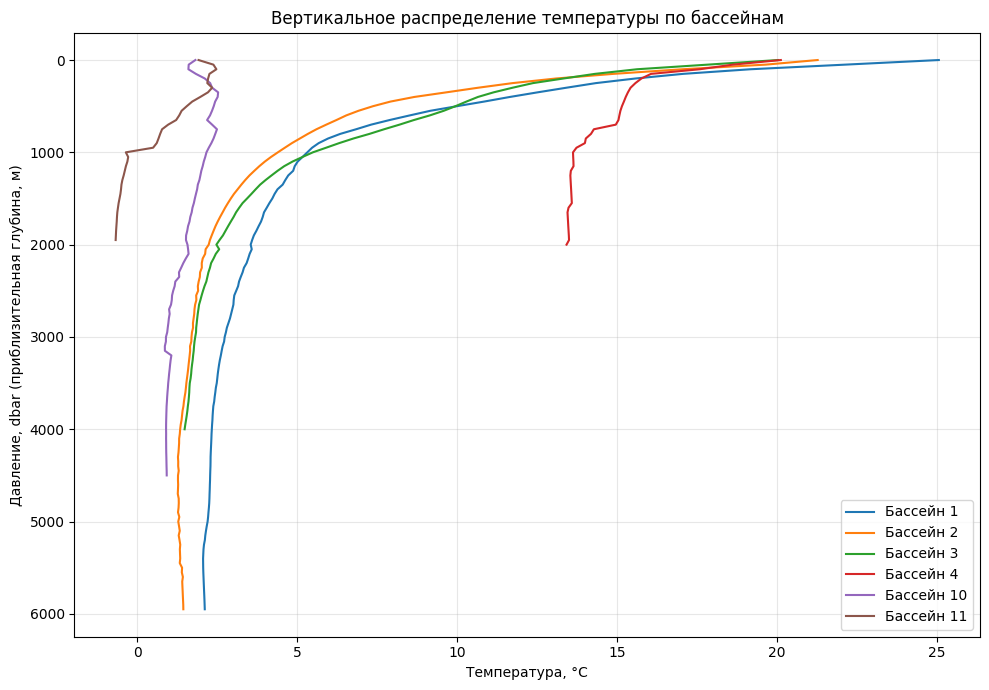

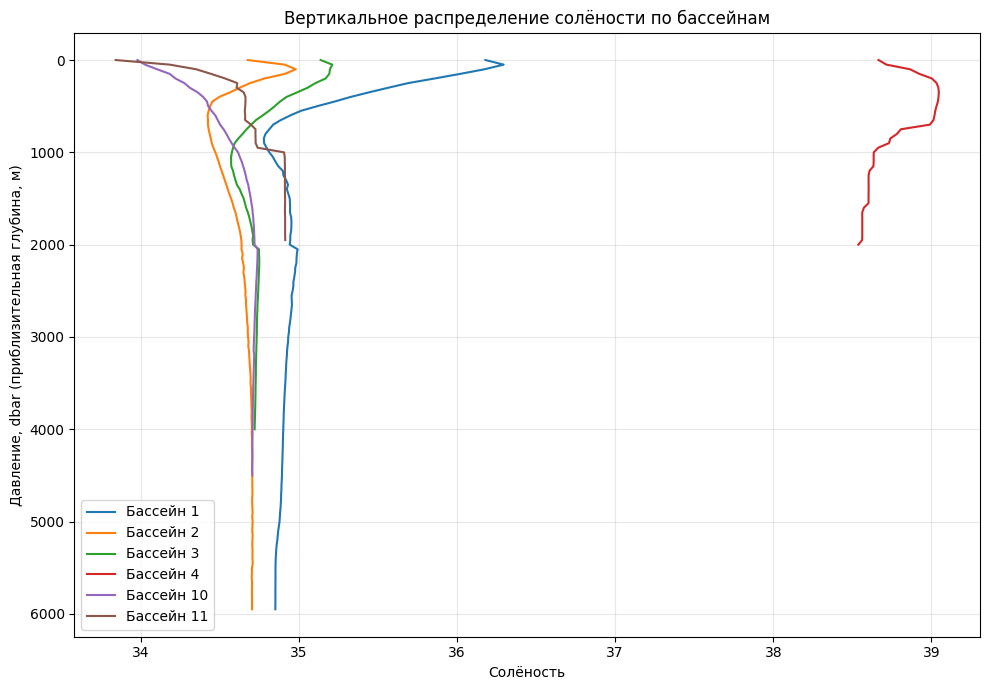

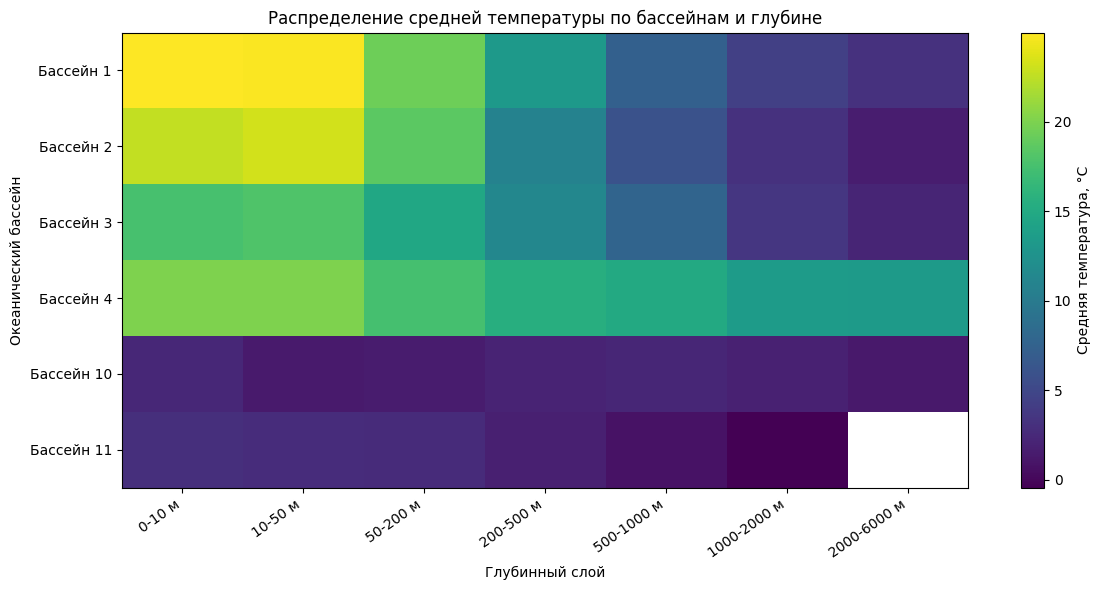

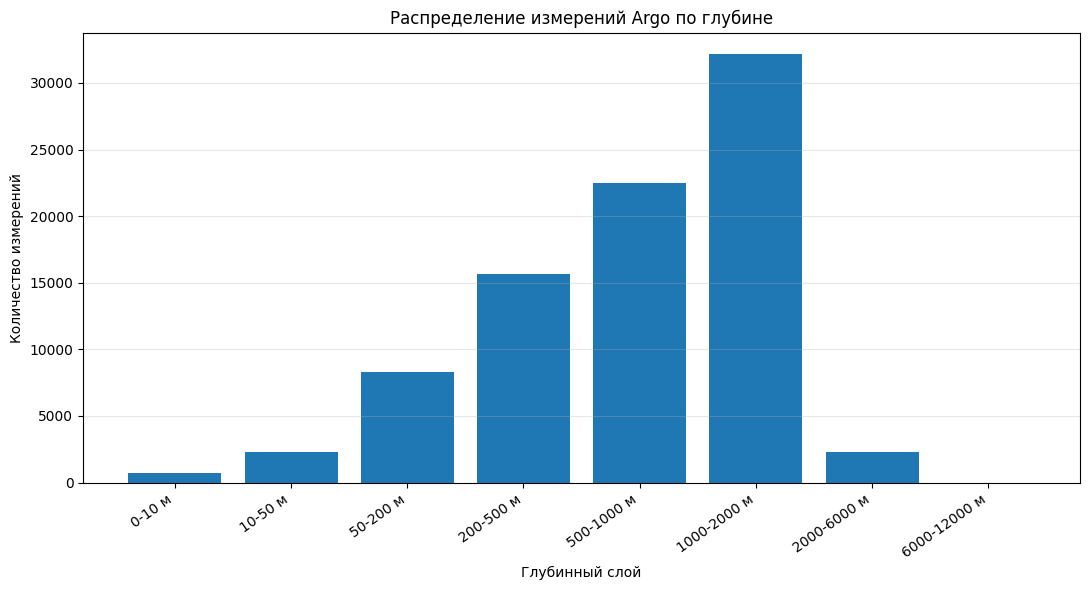

ВИЗУАЛИЗАЦИЯ ЗАВЕРШЕНА
Созданы 4 графика:
1. temperature_vertical_profile.png
2. salinity_vertical_profile.png
3. temperature_basin_depth_heatmap.png
4. measurements_by_depth.png


In [41]:

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

# Используем очищенную выборку
df_viz = df_analysis.copy()

os.makedirs("data/mart/figures", exist_ok=True)

# Глубина для графиков
df_viz["pressure"] = pd.to_numeric(
    df_viz["pressure"], errors="coerce"
)

df_viz["temperature"] = pd.to_numeric(
    df_viz["temperature"], errors="coerce"
)

df_viz["salinity"] = pd.to_numeric(
    df_viz["salinity"], errors="coerce"
)

# Убираем строки без необходимых значений
df_viz = df_viz.dropna(
    subset=["pressure", "temperature", "salinity", "basin"]
)

# ==========================================
# ГРАФИК 1. ВЕРТИКАЛЬНЫЙ ПРОФИЛЬ ТЕМПЕРАТУРЫ
# ==========================================

# Разбиваем давление на интервалы по 50 dbar
df_viz["pressure_bin"] = (
    (df_viz["pressure"] // 50) * 50
)

temp_profile = (
    df_viz.groupby(
        ["basin", "pressure_bin"],
        observed=True
    )["temperature"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 7))

for basin in sorted(temp_profile["basin"].unique()):
    part = temp_profile[temp_profile["basin"] == basin]

    plt.plot(
        part["temperature"],
        part["pressure_bin"],
        label=f"Бассейн {basin}"
    )

plt.gca().invert_yaxis()
plt.xlabel("Температура, °C")
plt.ylabel("Давление, dbar (приблизительная глубина, м)")
plt.title("Вертикальное распределение температуры по бассейнам")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "data/mart/figures/temperature_vertical_profile.png",
    dpi=300
)
plt.show()


# ==========================================
# ГРАФИК 2. ВЕРТИКАЛЬНЫЙ ПРОФИЛЬ СОЛЁНОСТИ
# ==========================================

salinity_profile = (
    df_viz.groupby(
        ["basin", "pressure_bin"],
        observed=True
    )["salinity"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(10, 7))

for basin in sorted(salinity_profile["basin"].unique()):
    part = salinity_profile[salinity_profile["basin"] == basin]

    plt.plot(
        part["salinity"],
        part["pressure_bin"],
        label=f"Бассейн {basin}"
    )

plt.gca().invert_yaxis()
plt.xlabel("Солёность")
plt.ylabel("Давление, dbar (приблизительная глубина, м)")
plt.title("Вертикальное распределение солёности по бассейнам")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "data/mart/figures/salinity_vertical_profile.png",
    dpi=300
)
plt.show()


# ==========================================
# ГРАФИК 3. ТЕМПЕРАТУРА ПО БАССЕЙНАМ И ГЛУБИНЕ
# ==========================================

heatmap_data = (
    df_ocean_mart_clean
    .pivot_table(
        index="basin",
        columns="depth_layer",
        values="temperature_mean",
        observed=False
    )
)

plt.figure(figsize=(12, 6))

plt.imshow(
    heatmap_data,
    aspect="auto",
    interpolation="nearest"
)

plt.colorbar(label="Средняя температура, °C")

plt.xticks(
    range(len(heatmap_data.columns)),
    heatmap_data.columns,
    rotation=35,
    ha="right"
)

plt.yticks(
    range(len(heatmap_data.index)),
    [f"Бассейн {x}" for x in heatmap_data.index]
)

plt.xlabel("Глубинный слой")
plt.ylabel("Океанический бассейн")
plt.title("Распределение средней температуры по бассейнам и глубине")

plt.tight_layout()

plt.savefig(
    "data/mart/figures/temperature_basin_depth_heatmap.png",
    dpi=300
)
plt.show()


# ==========================================
# ГРАФИК 4. КОЛИЧЕСТВО ИЗМЕРЕНИЙ ПО ГЛУБИНЕ
# ==========================================

depth_counts = (
    df_mart_clean["depth_layer"]
    .value_counts()
    .reindex(depth_labels, fill_value=0)
)

plt.figure(figsize=(11, 6))

plt.bar(
    depth_counts.index.astype(str),
    depth_counts.values
)

plt.xlabel("Глубинный слой")
plt.ylabel("Количество измерений")
plt.title("Распределение измерений Argo по глубине")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "data/mart/figures/measurements_by_depth.png",
    dpi=300
)
plt.show()


print("ВИЗУАЛИЗАЦИЯ ЗАВЕРШЕНА")
print("Созданы 4 графика:")
print("1. temperature_vertical_profile.png")
print("2. salinity_vertical_profile.png")
print("3. temperature_basin_depth_heatmap.png")
print("4. measurements_by_depth.png")


In [42]:

# ЭТАП: Анализ покрытия данных и статистики по бассейнам

import pandas as pd
import os

df_check = df_analysis.copy()

df_check["timestamp"] = pd.to_datetime(
    df_check["timestamp"], errors="coerce", utc=True
)

df_check["month"] = (
    df_check["timestamp"]
    .dt.tz_convert(None)
    .dt.to_period("M")
    .astype(str)
)

# Статистика по бассейнам, месяцам и источникам
basin_stats = (
    df_check
    .groupby(["basin", "month", "dataset_source"], dropna=False)
    .agg(
        measurements=("profile_id", "size"),
        profiles=("profile_id", "nunique"),
        temperature_mean=("temperature", "mean"),
        temperature_std=("temperature", "std"),
        salinity_mean=("salinity", "mean"),
        salinity_std=("salinity", "std"),
        pressure_max=("pressure", "max")
    )
    .reset_index()
)

print("СТАТИСТИКА ПО БАССЕЙНАМ И ИСТОЧНИКАМ")
display(basin_stats.round(3))

# Сохраняем результат
os.makedirs("data/mart", exist_ok=True)

basin_stats.to_csv(
    "data/mart/basin_source_statistics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Файл сохранён: data/mart/basin_source_statistics.csv")


СТАТИСТИКА ПО БАССЕЙНАМ И ИСТОЧНИКАМ


,basin,month,dataset_source,measurements,profiles,temperature_mean,temperature_std,salinity_mean,salinity_std,pressure_max
0,1,2024-11,huggingface_static,14648,20,9.368,6.485,35.208,0.644,5970.30
1,1,2026-11,argovis_api,2952,4,9.113,6.374,35.207,0.617,2011.36
2,2,2024-11,huggingface_static,33810,43,7.011,5.594,34.564,0.327,5992.60
3,2,2026-11,argovis_api,5971,7,7.561,6.497,34.640,0.348,5995.40
4,3,2024-11,huggingface_static,9558,12,8.316,5.717,34.839,0.329,4018.60
5,3,2026-11,argovis_api,3521,4,6.760,4.296,34.673,0.349,2022.10
6,4,2024-11,huggingface_static,372,1,17.007,2.013,39.220,0.063,745.70
7,4,2026-11,argovis_api,1021,1,14.162,0.986,38.654,0.196,2043.30
8,10,2024-11,huggingface_static,9383,12,2.015,1.498,34.499,0.266,4505.80
9,10,2026-11,argovis_api,1145,2,1.846,0.878,34.507,0.251,2005.64


Файл сохранён: data/mart/basin_source_statistics.csv


In [43]:

# ЭТАП: Формирование статистики по отдельным профилям Argo

import pandas as pd
import os

df_profile_stats = (
    df_analysis
    .groupby(
        ["profile_id", "basin", "dataset_source", "timestamp"],
        dropna=False
    )
    .agg(
        measurements=("pressure", "count"),
        temperature_mean=("temperature", "mean"),
        temperature_min=("temperature", "min"),
        temperature_max=("temperature", "max"),
        salinity_mean=("salinity", "mean"),
        salinity_min=("salinity", "min"),
        salinity_max=("salinity", "max"),
        pressure_min=("pressure", "min"),
        pressure_max=("pressure", "max")
    )
    .reset_index()
)

df_profile_stats["timestamp"] = pd.to_datetime(
    df_profile_stats["timestamp"],
    errors="coerce",
    utc=True
)

df_profile_stats["month"] = (
    df_profile_stats["timestamp"]
    .dt.strftime("%Y-%m")
)

print("КОЛИЧЕСТВО ПРОФИЛЕЙ:", len(df_profile_stats))

print("\nСТАТИСТИКА ПО БАССЕЙНАМ:")
display(
    df_profile_stats
    .groupby("basin")
    .agg(
        profiles=("profile_id", "nunique"),
        temperature_mean=("temperature_mean", "mean"),
        temperature_std=("temperature_mean", "std"),
        salinity_mean=("salinity_mean", "mean"),
        salinity_std=("salinity_mean", "std")
    )
    .round(3)
)

print("\nПРОФИЛИ С НАИБОЛЕЕ ВЫСОКОЙ СРЕДНЕЙ ТЕМПЕРАТУРОЙ:")
display(
    df_profile_stats
    .sort_values("temperature_mean", ascending=False)
    .head(10)
    .round(3)
)

os.makedirs("data/mart", exist_ok=True)

df_profile_stats.to_csv(
    "data/mart/argo_profile_statistics.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nФайл сохранён: data/mart/argo_profile_statistics.csv")


КОЛИЧЕСТВО ПРОФИЛЕЙ: 110

СТАТИСТИКА ПО БАССЕЙНАМ:


,profiles,temperature_mean,temperature_std,salinity_mean,salinity_std
basin,,,,,
1,24,10.087,2.594,35.286,0.388
2,50,7.546,2.618,34.543,0.236
3,16,8.324,2.552,34.795,0.197
4,2,15.585,2.012,38.937,0.400
10,14,1.628,1.644,34.490,0.124
11,4,1.720,0.555,34.570,0.413



ПРОФИЛИ С НАИБОЛЕЕ ВЫСОКОЙ СРЕДНЕЙ ТЕМПЕРАТУРОЙ:


,profile_id,basin,dataset_source,timestamp,measurements,temperature_mean,temperature_min,temperature_max,salinity_mean,salinity_min,salinity_max,pressure_min,pressure_max,month
106,7901141_074,4,huggingface_static,2024-11-27 18:54:40+00:00,372,17.007,15.701,21.215,39.220,39.139,39.366,0.30,745.70,2024-11
14,1902685_076,2,huggingface_static,2024-11-27 21:51:20.992000+00:00,223,16.482,4.290,25.924,34.673,34.117,35.104,3.58,1001.21,2024-11
22,3901604_300,1,huggingface_static,2024-11-27 19:07:54.999000+00:00,80,15.953,4.002,22.844,36.151,34.981,36.843,5.10,1948.20,2024-11
32,4902623_077,3,huggingface_static,2024-11-27 19:32:00+00:00,245,15.319,3.189,28.517,35.066,34.792,35.221,0.40,1969.70,2024-11
18,2902912_198,2,huggingface_static,2024-11-27 18:47:59.999000+00:00,263,14.891,6.957,21.748,34.458,33.956,34.706,2.35,525.75,2024-11
44,4903562_072,1,huggingface_static,2024-11-27 21:38:10.002000+00:00,506,14.809,5.080,28.713,35.705,34.879,37.052,1.00,1001.16,2024-11
43,4903552_267,1,argovis_api,2026-11-24 04:32:19+00:00,444,14.583,5.591,28.339,35.676,34.900,36.911,0.44,875.40,2026-11
46,4903817_156,4,argovis_api,2026-11-24 03:52:59.999000+00:00,1021,14.162,13.419,18.967,38.654,37.843,38.890,3.30,2043.30,2026-11
69,5906462_111,2,huggingface_static,2024-11-27 22:53:49.002000+00:00,509,12.235,2.251,27.450,34.882,34.359,35.728,4.52,1998.02,2024-11
94,7900548_173,1,huggingface_static,2024-11-27 19:34:20+00:00,97,12.139,4.058,24.851,35.844,35.056,37.412,5.80,2002.10,2024-11



Файл сохранён: data/mart/argo_profile_statistics.csv


In [44]:

# ЭТАП: Поиск потенциальных температурных и солёностных аномалий

import pandas as pd
import numpy as np
import os

df_anomaly = df_analysis.copy()

# Приводим показатели к числовому формату
for col in ["pressure", "temperature", "salinity"]:
    df_anomaly[col] = pd.to_numeric(
        df_anomaly[col], errors="coerce"
    )

# Разделяем измерения по глубине
depth_bins = [0, 10, 50, 200, 500, 1000, 2000, 6000, 12000]
depth_labels = [
    "0-10 м", "10-50 м", "50-200 м", "200-500 м",
    "500-1000 м", "1000-2000 м", "2000-6000 м",
    "6000-12000 м"
]

df_anomaly["depth_layer"] = pd.cut(
    df_anomaly["pressure"],
    bins=depth_bins,
    labels=depth_labels,
    include_lowest=True
)

# Робастная оценка отклонений:
# медиана и MAD рассчитываются отдельно для каждого бассейна и слоя
group_cols = ["basin", "depth_layer"]

for col in ["temperature", "salinity"]:
    grouped = df_anomaly.groupby(
        group_cols, observed=True
    )[col]

    median = grouped.transform("median")
    mad = grouped.transform(
        lambda x: (x - x.median()).abs().median()
    )
    count = grouped.transform("count")

    # Робастный z-score
    scale = 1.4826 * mad
    df_anomaly[f"{col}_robust_z"] = (
        (df_anomaly[col] - median) / scale.replace(0, np.nan)
    )

    # Группы с малым количеством измерений не оцениваем
    df_anomaly[f"{col}_anomaly"] = (
        (count >= 30) &
        (df_anomaly[f"{col}_robust_z"].abs() > 3.5)
    )

# Общий признак потенциальной аномалии
df_anomaly["potential_anomaly"] = (
    df_anomaly["temperature_anomaly"] |
    df_anomaly["salinity_anomaly"]
)

# Вывод результатов
anomalies = df_anomaly[
    df_anomaly["potential_anomaly"]
].copy()

print("ВСЕГО ИЗМЕРЕНИЙ:", len(df_anomaly))
print("ПОТЕНЦИАЛЬНЫХ АНОМАЛЬНЫХ ИЗМЕРЕНИЙ:", len(anomalies))

print("\nАНОМАЛИИ ПО БАССЕЙНАМ:")
display(
    anomalies.groupby("basin", observed=True)
    .agg(
        anomaly_measurements=("profile_id", "size"),
        affected_profiles=("profile_id", "nunique"),
        temperature_anomalies=("temperature_anomaly", "sum"),
        salinity_anomalies=("salinity_anomaly", "sum")
    )
    .reset_index()
)

print("\nПРИМЕРЫ ПОТЕНЦИАЛЬНЫХ АНОМАЛИЙ:")
display(
    anomalies[
        [
            "profile_id", "basin", "dataset_source",
            "pressure", "depth_layer",
            "temperature", "salinity",
            "temperature_robust_z",
            "salinity_robust_z"
        ]
    ].head(20).round(3)
)

# Сохраняем результаты
os.makedirs("data/mart", exist_ok=True)

anomalies.to_csv(
    "data/mart/potential_ocean_anomalies.csv",
    index=False,
    encoding="utf-8-sig"
)

df_anomaly.to_csv(
    "data/mart/ocean_measurements_with_anomaly_flags.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nФайлы сохранены:")
print("data/mart/potential_ocean_anomalies.csv")
print("data/mart/ocean_measurements_with_anomaly_flags.csv")


ВСЕГО ИЗМЕРЕНИЙ: 83981
ПОТЕНЦИАЛЬНЫХ АНОМАЛЬНЫХ ИЗМЕРЕНИЙ: 3452

АНОМАЛИИ ПО БАССЕЙНАМ:


,basin,anomaly_measurements,affected_profiles,temperature_anomalies,salinity_anomalies
0,1,335,7,306,221
1,2,1305,26,120,1235
2,3,204,7,91,113
3,10,1308,13,328,981
4,11,300,2,0,300



ПРИМЕРЫ ПОТЕНЦИАЛЬНЫХ АНОМАЛИЙ:


,profile_id,basin,dataset_source,pressure,depth_layer,temperature,salinity,temperature_robust_z,salinity_robust_z
2277,4903409_150,2,huggingface_static,502.00,500-1000 м,6.067,33.954,0.278,-3.545
2278,4903409_150,2,huggingface_static,503.96,500-1000 м,6.038,33.956,0.253,-3.537
2279,4903409_150,2,huggingface_static,506.00,500-1000 м,5.986,33.956,0.209,-3.536
2280,4903409_150,2,huggingface_static,508.00,500-1000 м,5.952,33.954,0.180,-3.547
2281,4903409_150,2,huggingface_static,510.00,500-1000 м,5.937,33.955,0.168,-3.539
2282,4903409_150,2,huggingface_static,512.00,500-1000 м,5.897,33.958,0.134,-3.520
2283,4903409_150,2,huggingface_static,514.00,500-1000 м,5.854,33.958,0.097,-3.518
2284,4903409_150,2,huggingface_static,516.04,500-1000 м,5.827,33.959,0.074,-3.513
2285,4903409_150,2,huggingface_static,518.04,500-1000 м,5.805,33.959,0.056,-3.512
2527,4903409_150,2,huggingface_static,1001.96,1000-2000 м,3.538,34.373,0.687,-3.890



Файлы сохранены:
data/mart/potential_ocean_anomalies.csv
data/mart/ocean_measurements_with_anomaly_flags.csv


In [45]:

# ЭТАП: Анализ потенциальных аномалий на уровне профилей

import pandas as pd
import os

df_anomalies = pd.read_csv(
    "data/mart/potential_ocean_anomalies.csv"
)

# Порог статистического отклонения
threshold = 3.0

df_anomalies["temperature_anomaly"] = (
    df_anomalies["temperature_robust_z"].abs() > threshold
)

df_anomalies["salinity_anomaly"] = (
    df_anomalies["salinity_robust_z"].abs() > threshold
)

# Статистика по каждому профилю
profile_anomalies = (
    df_anomalies
    .groupby(
        ["profile_id", "basin", "dataset_source"],
        dropna=False
    )
    .agg(
        anomaly_measurements=("profile_id", "size"),
        temperature_anomalies=("temperature_anomaly", "sum"),
        salinity_anomalies=("salinity_anomaly", "sum"),
        max_temperature_deviation=(
            "temperature_robust_z",
            lambda x: x.abs().max()
        ),
        max_salinity_deviation=(
            "salinity_robust_z",
            lambda x: x.abs().max()
        )
    )
    .reset_index()
)

profile_anomalies["both_parameters"] = (
    (profile_anomalies["temperature_anomalies"] > 0) &
    (profile_anomalies["salinity_anomalies"] > 0)
)

print("ВСЕГО ПРОФИЛЕЙ С ПОТЕНЦИАЛЬНЫМИ АНОМАЛИЯМИ:",
      profile_anomalies["profile_id"].nunique())

print("\nТОП-15 ПРОФИЛЕЙ ПО ЧИСЛУ АНОМАЛЬНЫХ ИЗМЕРЕНИЙ:")

display(
    profile_anomalies
    .sort_values("anomaly_measurements", ascending=False)
    .head(15)
    .round(3)
)

print("\nСТАТИСТИКА ПО БАССЕЙНАМ:")

basin_anomaly_stats = (
    profile_anomalies
    .groupby("basin")
    .agg(
        affected_profiles=("profile_id", "nunique"),
        anomaly_measurements=("anomaly_measurements", "sum"),
        profiles_with_both_parameters=("both_parameters", "sum"),
        max_temperature_deviation=("max_temperature_deviation", "max"),
        max_salinity_deviation=("max_salinity_deviation", "max")
    )
    .reset_index()
)

display(basin_anomaly_stats.round(3))

# Сохранение результатов
os.makedirs("data/mart", exist_ok=True)

profile_anomalies.to_csv(
    "data/mart/anomalies_by_profile.csv",
    index=False,
    encoding="utf-8-sig"
)

basin_anomaly_stats.to_csv(
    "data/mart/anomalies_by_basin_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nФайлы сохранены:")
print("data/mart/anomalies_by_profile.csv")
print("data/mart/anomalies_by_basin_summary.csv")


ВСЕГО ПРОФИЛЕЙ С ПОТЕНЦИАЛЬНЫМИ АНОМАЛИЯМИ: 55

ТОП-15 ПРОФИЛЕЙ ПО ЧИСЛУ АНОМАЛЬНЫХ ИЗМЕРЕНИЙ:


,profile_id,basin,dataset_source,anomaly_measurements,temperature_anomalies,salinity_anomalies,max_temperature_deviation,max_salinity_deviation,both_parameters
36,5906906_075,10,huggingface_static,449,55,395,5.294,18.967,True
50,7900940_176,10,huggingface_static,319,263,56,5.443,4.150,True
43,5907282_167,11,argovis_api,250,0,250,2.034,11.342,False
37,5906907_075,10,huggingface_static,243,3,240,4.244,11.568,True
41,5907028_007,2,huggingface_static,212,10,212,3.194,5.223,True
16,3902586_020,1,huggingface_static,198,198,179,6.156,4.086,True
42,5907035_002,2,huggingface_static,164,0,164,1.672,5.699,False
25,5905253_266,2,huggingface_static,164,0,164,2.469,5.121,False
24,5905251_264,2,huggingface_static,142,0,142,2.306,5.151,False
30,5906110_190D,2,huggingface_static,141,0,141,2.037,5.245,False



СТАТИСТИКА ПО БАССЕЙНАМ:


,basin,affected_profiles,anomaly_measurements,profiles_with_both_parameters,max_temperature_deviation,max_salinity_deviation
0,1,7,335,4,6.156,4.894
1,2,26,1305,7,4.707,5.699
2,3,7,204,2,3.873,6.954
3,10,13,1308,6,5.443,18.967
4,11,2,300,0,2.034,11.492



Файлы сохранены:
data/mart/anomalies_by_profile.csv
data/mart/anomalies_by_basin_summary.csv


In [47]:

# ЭТАП: Проверка наиболее выраженных аномалий — исправленная версия

import pandas as pd
import numpy as np
import os

df_anomalies = pd.read_csv(
    "data/mart/potential_ocean_anomalies.csv"
)

# 1. Наиболее сильные отклонения солёности
print("ТОП-15 САМЫХ СИЛЬНЫХ ОТКЛОНЕНИЙ СОЛЁНОСТИ:")

display(
    df_anomalies.assign(
        abs_z=lambda x: x["salinity_robust_z"].abs()
    )
    .sort_values("abs_z", ascending=False)
    [[
        "profile_id", "basin", "pressure",
        "temperature", "salinity",
        "salinity_robust_z"
    ]]
    .head(15)
    .round(3)
)

# 2. Распределение аномалий по глубинным слоям
depth_bins = [0, 10, 50, 200, 500, 1000, 2000, 6000, 12000]

depth_labels = [
    "0-10 м", "10-50 м", "50-200 м",
    "200-500 м", "500-1000 м",
    "1000-2000 м", "2000-6000 м",
    "6000-12000 м"
]

df_anomalies["depth_layer"] = pd.cut(
    df_anomalies["pressure"],
    bins=depth_bins,
    labels=depth_labels,
    include_lowest=True
)

print("\nАНОМАЛИИ ПО ГЛУБИННЫМ СЛОЯМ:")

depth_anomaly_stats = (
    df_anomalies
    .groupby("depth_layer", observed=True)
    .agg(
        anomaly_measurements=("profile_id", "size"),
        affected_profiles=("profile_id", "nunique"),
        mean_temperature=("temperature", "mean"),
        mean_salinity=("salinity", "mean")
    )
    .reset_index()
)

display(depth_anomaly_stats.round(3))

# 3. Проверка выбранных профилей
df_profile_check = df_analysis.copy()

df_profile_check["depth_layer"] = pd.cut(
    pd.to_numeric(df_profile_check["pressure"], errors="coerce"),
    bins=depth_bins,
    labels=depth_labels,
    include_lowest=True
)

selected_profiles = [
    "5906906_075",
    "7900940_176",
    "5907282_167"
]

print("\nСТАТИСТИКА ВЫБРАННЫХ ПРОФИЛЕЙ:")

for profile_id in selected_profiles:

    profile = df_profile_check[
        df_profile_check["profile_id"].astype(str) == profile_id
    ]

    print(f"\nПРОФИЛЬ: {profile_id}")

    if profile.empty:
        print("Профиль не найден")
        continue

    print("Бассейн:", profile["basin"].iloc[0])
    print("Источник:", profile["dataset_source"].iloc[0])
    print("Измерений:", len(profile))

    print("\nТемпература:")
    print(profile["temperature"].describe().round(3))

    print("\nСолёность:")
    print(profile["salinity"].describe().round(3))

    display(
        profile
        .groupby("depth_layer", observed=True)
        .agg(
            measurements=("pressure", "count"),
            temperature_mean=("temperature", "mean"),
            salinity_mean=("salinity", "mean"),
            pressure_min=("pressure", "min"),
            pressure_max=("pressure", "max")
        )
        .round(3)
    )

# 4. Сохранение
os.makedirs("data/mart", exist_ok=True)

depth_anomaly_stats.to_csv(
    "data/mart/anomalies_by_depth.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nФайл сохранён: data/mart/anomalies_by_depth.csv")


ТОП-15 САМЫХ СИЛЬНЫХ ОТКЛОНЕНИЙ СОЛЁНОСТИ:


,profile_id,basin,pressure,temperature,salinity,salinity_robust_z
1259,5906906_075,10,1002.00,3.187,34.324,-18.967
1260,5906906_075,10,1004.00,3.182,34.325,-18.910
1261,5906906_075,10,1005.96,3.176,34.326,-18.842
1262,5906906_075,10,1007.96,3.174,34.328,-18.775
1268,5906906_075,10,1019.96,3.139,34.328,-18.756
1269,5906906_075,10,1022.00,3.136,34.328,-18.746
1265,5906906_075,10,1014.00,3.169,34.328,-18.746
1266,5906906_075,10,1016.00,3.164,34.328,-18.746
1264,5906906_075,10,1012.00,3.170,34.328,-18.737
1263,5906906_075,10,1009.96,3.172,34.328,-18.737



АНОМАЛИИ ПО ГЛУБИННЫМ СЛОЯМ:


,depth_layer,anomaly_measurements,affected_profiles,mean_temperature,mean_salinity
0,0-10 м,35,5,3.288,33.330
1,10-50 м,43,3,5.794,32.805
2,50-200 м,245,9,3.869,34.473
3,200-500 м,346,10,6.797,34.804
4,500-1000 м,517,11,2.167,34.947
5,1000-2000 м,2234,29,3.982,34.555
6,2000-6000 м,32,9,2.223,34.684



СТАТИСТИКА ВЫБРАННЫХ ПРОФИЛЕЙ:

ПРОФИЛЬ: 5906906_075
Бассейн: 10
Источник: huggingface_static
Измерений: 1012

Температура:
count    1012.000
mean        3.736
std         1.331
min         2.177
25%         2.569
50%         3.179
75%         5.124
max         6.346
Name: temperature, dtype: float64

Солёность:
count    1012.000
mean       34.361
std         0.203
min        34.029
25%        34.200
50%        34.323
75%        34.558
max        34.684
Name: salinity, dtype: float64


,measurements,temperature_mean,salinity_mean,pressure_min,pressure_max
depth_layer,,,,,
0-10 м,9,6.344,34.035,1.08,9.00
10-50 м,21,6.319,34.035,10.04,48.00
50-200 м,75,5.585,34.046,50.04,197.92
200-500 м,151,5.583,34.185,200.04,500.00
500-1000 м,250,4.068,34.240,502.00,1000.00
1000-2000 м,500,2.599,34.538,1002.00,1999.96
2000-6000 м,6,2.186,34.683,2002.04,2011.56



ПРОФИЛЬ: 7900940_176
Бассейн: 10
Источник: huggingface_static
Измерений: 354

Температура:
count    354.000
mean      -1.874
std        0.021
min       -1.893
25%       -1.890
50%       -1.886
75%       -1.857
max       -1.819
Name: temperature, dtype: float64

Солёность:
count    354.000
mean      34.518
std        0.055
min       34.378
25%       34.490
50%       34.536
75%       34.562
max       34.575
Name: salinity, dtype: float64


,measurements,temperature_mean,salinity_mean,pressure_min,pressure_max
depth_layer,,,,,
10-50 м,16,-1.840,34.382,19.05,48.95
50-200 м,75,-1.845,34.450,50.93,198.95
200-500 м,150,-1.880,34.531,200.93,498.92
500-1000 м,113,-1.889,34.566,500.92,724.82



ПРОФИЛЬ: 5907282_167
Бассейн: 11
Источник: argovis_api
Измерений: 503

Температура:
count    503.000
mean       0.904
std        1.531
min       -0.386
25%       -0.178
50%        0.189
75%        1.378
max        4.528
Name: temperature, dtype: float64

Солёность:
count    503.000
mean      34.911
std        0.034
min       34.882
25%       34.894
50%       34.899
75%       34.904
max       35.001
Name: salinity, dtype: float64


,measurements,temperature_mean,salinity_mean,pressure_min,pressure_max
depth_layer,,,,,
0-10 м,4,4.518,34.998,2.95,8.95
10-50 м,20,4.520,34.998,11.00,48.95
50-200 м,75,3.405,34.957,50.95,199.00
200-500 м,150,0.859,34.892,201.10,499.10
500-1000 м,250,-0.145,34.900,501.00,998.95
1000-2000 м,4,-0.384,34.904,1000.90,1006.00



Файл сохранён: data/mart/anomalies_by_depth.csv


In [48]:

# ЭТАП: Классификация профилей по доле аномальных измерений

import pandas as pd
import numpy as np
import os

# Все измерения и количество измерений в каждом профиле
profile_totals = (
    df_analysis
    .groupby(
        ["profile_id", "basin", "dataset_source"],
        dropna=False
    )
    .size()
    .reset_index(name="total_measurements")
)

# Количество потенциальных аномалий
anomaly_counts = (
    df_anomalies
    .groupby(
        ["profile_id", "basin", "dataset_source"],
        dropna=False
    )
    .size()
    .reset_index(name="anomaly_measurements")
)

# Объединяем статистику
df_monitoring = profile_totals.merge(
    anomaly_counts,
    on=["profile_id", "basin", "dataset_source"],
    how="left"
)

df_monitoring["anomaly_measurements"] = (
    df_monitoring["anomaly_measurements"]
    .fillna(0)
    .astype(int)
)

# Доля потенциальных аномалий
df_monitoring["anomaly_share_pct"] = (
    df_monitoring["anomaly_measurements"]
    / df_monitoring["total_measurements"] * 100
)

# Аналитические уровни предупреждения
conditions = [
    df_monitoring["anomaly_share_pct"] == 0,
    df_monitoring["anomaly_share_pct"] <= 1,
    df_monitoring["anomaly_share_pct"] <= 5,
    df_monitoring["anomaly_share_pct"] > 5
]

levels = [
    "Отклонения не обнаружены",
    "Низкий",
    "Умеренный",
    "Высокий"
]

df_monitoring["monitoring_level"] = np.select(
    conditions,
    levels,
    default="Не определён"
)

# Сводка по уровням
print("РАСПРЕДЕЛЕНИЕ ПРОФИЛЕЙ ПО УРОВНЯМ:")

level_summary = (
    df_monitoring
    .groupby("monitoring_level", observed=True)
    .agg(
        profiles=("profile_id", "nunique"),
        measurements=("total_measurements", "sum"),
        anomaly_measurements=("anomaly_measurements", "sum")
    )
    .reset_index()
)

display(level_summary)

# Топ профилей с наибольшей долей отклонений
print("\nПРОФИЛИ С НАИБОЛЬШЕЙ ДОЛЕЙ ОТКЛОНЕНИЙ:")

display(
    df_monitoring
    .sort_values("anomaly_share_pct", ascending=False)
    .head(15)
    [[
        "profile_id",
        "basin",
        "dataset_source",
        "total_measurements",
        "anomaly_measurements",
        "anomaly_share_pct",
        "monitoring_level"
    ]]
    .round(2)
)

# Сводка по бассейнам
basin_monitoring = (
    df_monitoring
    .groupby("basin")
    .agg(
        profiles=("profile_id", "nunique"),
        mean_anomaly_share=("anomaly_share_pct", "mean"),
        profiles_high=("monitoring_level",
                       lambda x: (x == "Высокий").sum()),
        profiles_moderate=("monitoring_level",
                           lambda x: (x == "Умеренный").sum())
    )
    .reset_index()
)

print("\nСВОДКА ПО БАССЕЙНАМ:")
display(basin_monitoring.round(2))

# Сохранение
os.makedirs("data/mart", exist_ok=True)

df_monitoring.to_csv(
    "data/mart/ocean_profile_monitoring.csv",
    index=False,
    encoding="utf-8-sig"
)

level_summary.to_csv(
    "data/mart/monitoring_level_summary.csv",
    index=False,
    encoding="utf-8-sig"
)

basin_monitoring.to_csv(
    "data/mart/monitoring_by_basin.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nТри файла мониторинга сохранены в data/mart/")


РАСПРЕДЕЛЕНИЕ ПРОФИЛЕЙ ПО УРОВНЯМ:


,monitoring_level,profiles,measurements,anomaly_measurements
0,Высокий,26,18769,3126
1,Низкий,12,11003,53
2,Отклонения не обнаружены,55,42930,0
3,Умеренный,17,11279,273



ПРОФИЛИ С НАИБОЛЬШЕЙ ДОЛЕЙ ОТКЛОНЕНИЙ:


,profile_id,basin,dataset_source,total_measurements,anomaly_measurements,anomaly_share_pct,monitoring_level
99,7900940_176,10,huggingface_static,354,319,90.11,Высокий
86,5907282_167,11,argovis_api,503,250,49.70,Высокий
79,5906906_075,10,huggingface_static,1012,449,44.37,Высокий
80,5906907_075,10,huggingface_static,1009,243,24.08,Высокий
84,5907028_007,2,huggingface_static,914,212,23.19,Высокий
85,5907035_002,2,huggingface_static,763,164,21.49,Высокий
109,7902195_035,11,huggingface_static,243,50,20.58,Высокий
29,3902586_020,1,huggingface_static,996,198,19.88,Высокий
53,5905253_266,2,huggingface_static,1010,164,16.24,Высокий
100,7900981_101,10,huggingface_static,134,19,14.18,Высокий



СВОДКА ПО БАССЕЙНАМ:


,basin,profiles,mean_anomaly_share,profiles_high,profiles_moderate
0,1,24,2.17,4,2
1,2,50,3.21,12,6
2,3,16,1.39,2,2
3,4,2,0.00,0,0
4,10,14,15.18,6,7
5,11,4,17.57,2,0



Три файла мониторинга сохранены в data/mart/


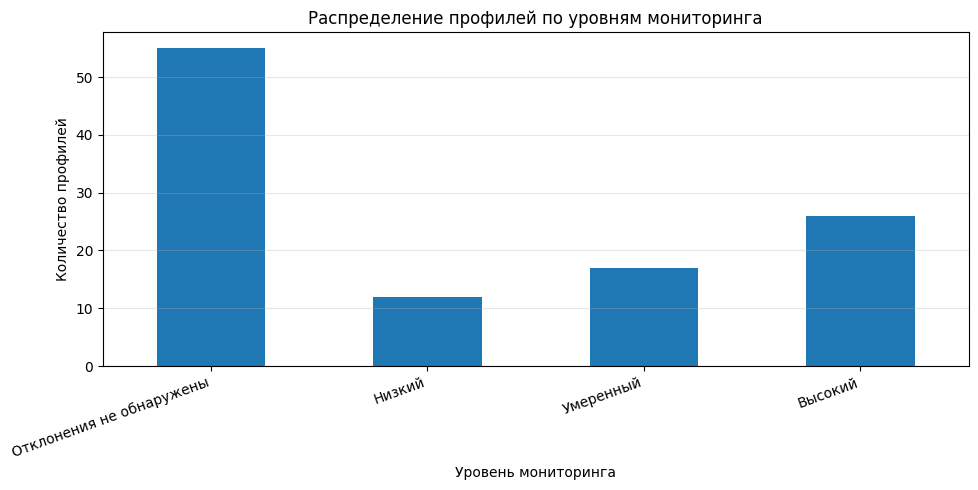

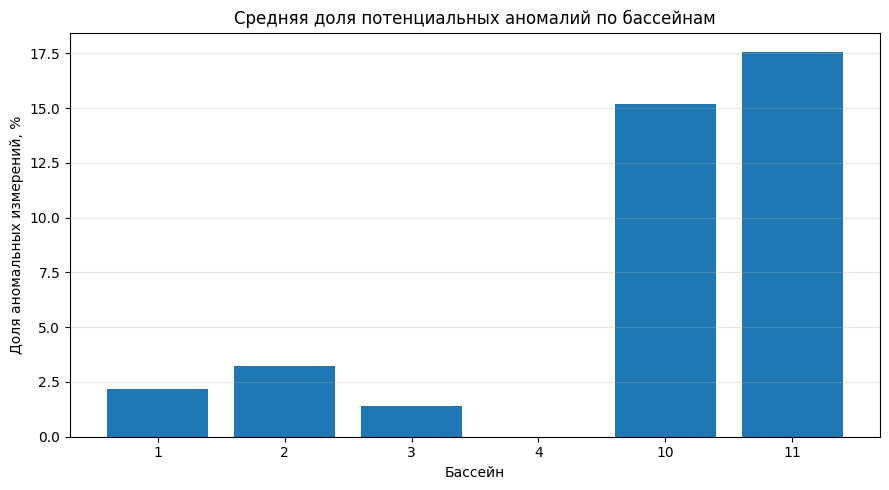

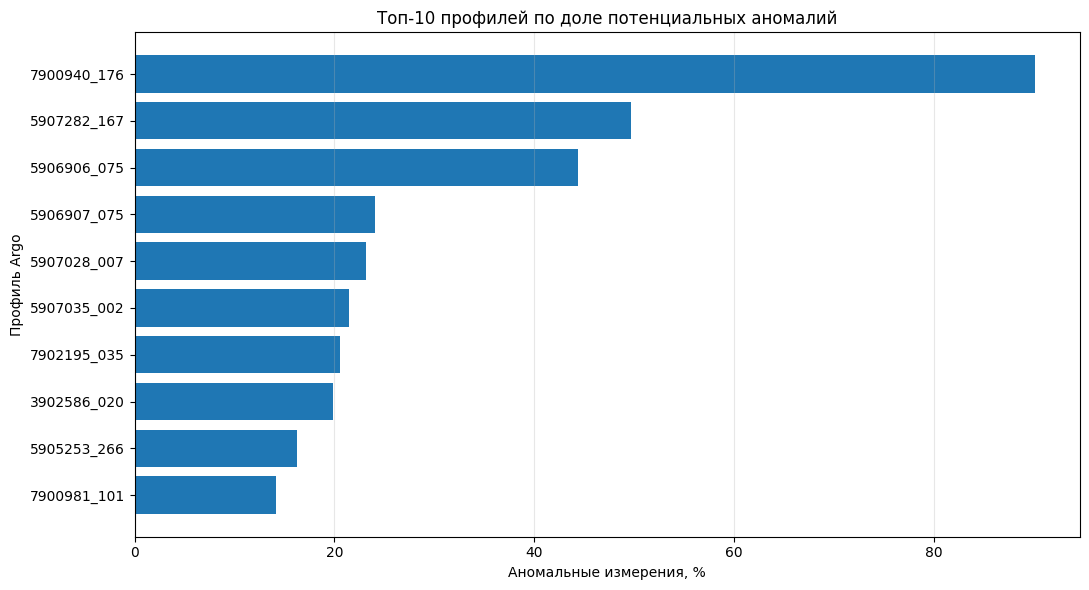

Три графика сохранены в data/mart/figures/


In [49]:

# ЭТАП: Итоговая визуализация системы мониторинга

import matplotlib.pyplot as plt
import pandas as pd
import os

os.makedirs("data/mart/figures", exist_ok=True)

# 1. Распределение профилей по уровням
level_order = [
    "Отклонения не обнаружены",
    "Низкий",
    "Умеренный",
    "Высокий"
]

level_plot = (
    df_monitoring["monitoring_level"]
    .value_counts()
    .reindex(level_order, fill_value=0)
)

plt.figure(figsize=(10, 5))
level_plot.plot(kind="bar")
plt.title("Распределение профилей по уровням мониторинга")
plt.xlabel("Уровень мониторинга")
plt.ylabel("Количество профилей")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "data/mart/figures/monitoring_levels.png",
    dpi=300
)
plt.show()

# 2. Средняя доля аномалий по бассейнам
basin_plot = basin_monitoring.sort_values("basin")

plt.figure(figsize=(9, 5))
plt.bar(
    basin_plot["basin"].astype(str),
    basin_plot["mean_anomaly_share"]
)
plt.title("Средняя доля потенциальных аномалий по бассейнам")
plt.xlabel("Бассейн")
plt.ylabel("Доля аномальных измерений, %")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "data/mart/figures/anomaly_share_by_basin.png",
    dpi=300
)
plt.show()

# 3. Топ-10 профилей
top_profiles = (
    df_monitoring
    .sort_values("anomaly_share_pct", ascending=False)
    .head(10)
    .sort_values("anomaly_share_pct")
)

plt.figure(figsize=(11, 6))
plt.barh(
    top_profiles["profile_id"].astype(str),
    top_profiles["anomaly_share_pct"]
)
plt.title("Топ-10 профилей по доле потенциальных аномалий")
plt.xlabel("Аномальные измерения, %")
plt.ylabel("Профиль Argo")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "data/mart/figures/top_anomalous_profiles.png",
    dpi=300
)
plt.show()

print("Три графика сохранены в data/mart/figures/")


In [50]:

import os

expected_files = [
    "data/processed/argo_analysis_clean.csv",
    "data/processed/argo_rejected_measurements.csv",
    "data/processed/argo_core_good.csv",
    "data/mart/ocean_depth_basin_month_mart_clean.csv",
    "data/mart/potential_ocean_anomalies.csv",
    "data/mart/ocean_measurements_with_anomaly_flags.csv",
    "data/mart/ocean_profile_monitoring.csv",
    "data/mart/monitoring_level_summary.csv",
    "data/mart/monitoring_by_basin.csv",
    "data/mart/basin_source_statistics.csv",
    "data/mart/argo_profile_statistics.csv",
    "data/raw/static/argo_profiles_sample.jsonl",
]

print("ПРОВЕРКА ФАЙЛОВ ПРОЕКТА\n")

for file in expected_files:
    status = "OK" if os.path.exists(file) else "НЕТ ФАЙЛА"
    if os.path.exists(file):
        size = round(os.path.getsize(file) / 1024, 1)
        print(f"{status}: {file} ({size} KB)")
    else:
        print(f"{status}: {file}")

print("\nГРАФИКИ:")
figures_dir = "data/mart/figures"

if os.path.exists(figures_dir):
    for file in sorted(os.listdir(figures_dir)):
        print("OK:", os.path.join(figures_dir, file))
else:
    print("Папка с графиками не найдена")


ПРОВЕРКА ФАЙЛОВ ПРОЕКТА

OK: data/processed/argo_analysis_clean.csv (23873.4 KB)
OK: data/processed/argo_rejected_measurements.csv (4689.2 KB)
OK: data/processed/argo_core_good.csv (23658.2 KB)
OK: data/mart/ocean_depth_basin_month_mart_clean.csv (12.0 KB)
OK: data/mart/potential_ocean_anomalies.csv (1196.5 KB)
OK: data/mart/ocean_measurements_with_anomaly_flags.csv (29531.4 KB)
OK: data/mart/ocean_profile_monitoring.csv (8.8 KB)
OK: data/mart/monitoring_level_summary.csv (0.2 KB)
OK: data/mart/monitoring_by_basin.csv (0.2 KB)
OK: data/mart/basin_source_statistics.csv (1.5 KB)
OK: data/mart/argo_profile_statistics.csv (17.4 KB)
OK: data/raw/static/argo_profiles_sample.jsonl (4353.2 KB)

ГРАФИКИ:
OK: data/mart/figures/anomaly_share_by_basin.png
OK: data/mart/figures/measurements_by_depth.png
OK: data/mart/figures/monitoring_levels.png
OK: data/mart/figures/salinity_vertical_profile.png
OK: data/mart/figures/temperature_basin_depth_heatmap.png
OK: data/mart/figures/temperature_vertical_p

In [51]:

import os
import shutil

# Создаём папку для оперативных исходных данных
os.makedirs("data/raw/dynamic", exist_ok=True)

# Копируем JSONL в папку динамических данных
source = "data/raw/static/argo_profiles_sample.jsonl"
destination = "data/raw/dynamic/argo_profiles_sample.jsonl"

if os.path.exists(source):
    shutil.copy2(source, destination)
    print("Оперативные данные подготовлены:", destination)

# Создаём папку для ноутбука
os.makedirs("notebooks", exist_ok=True)

print("Папка notebooks подготовлена.")

Оперативные данные подготовлены: data/raw/dynamic/argo_profiles_sample.jsonl
Папка notebooks подготовлена.


In [52]:

import shutil
import os

# Создаём архив с данными и графиками
shutil.make_archive(
    "/content/argo_ocean_monitoring_data",
    "zip",
    root_dir="/content",
    base_dir="data"
)

print("Архив подготовлен!")
print("Размер:", round(
    os.path.getsize("/content/argo_ocean_monitoring_data.zip") / 1024 / 1024,
    2
), "MB")

from google.colab import files
files.download("/content/argo_ocean_monitoring_data.zip")


Архив подготовлен!
Размер: 9.4 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>